# Лабораторная работа №1. Линейная регрессия

МАИ, ФИИТ, 3 курс · «Концепции машинного обучения»

**Выполнил: Месропян Арман Эдвардович, группа М8О-313БВ-24**

Задача — предсказать `RiskScore` по данным заявки. Проверяю собственные реализации методов, сравниваю варианты линейной регрессии и оцениваю итоговую модель по MSE.

Для запуска нужны `train.csv`, `test.csv` и `ex.csv` в папке `data`. В Colab её можно создать в панели «Файлы».

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from scipy.linalg import solve
from scipy.special import erf
from sklearn.linear_model import (
    ElasticNet as SkElastic, Lasso as SkLasso, LinearRegression as SkLinear,
    Ridge as SkRidge, SGDRegressor,
)
from sklearn.metrics import (
    mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score,
)
from sklearn.model_selection import KFold as SkKFold, LeaveOneOut as SkLeaveOneOut
from sklearn.preprocessing import MinMaxScaler as SkMinMax, StandardScaler
from threadpoolctl import threadpool_limits

threadpool_limits(limits=2)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .22, "font.size": 10})
pd.set_option("display.max_rows", 45)
TARGET = "RiskScore"
SEED = 20261119
DATA = Path("data")
raw_train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
example = pd.read_csv(DATA / "ex.csv")
predictor_columns = raw_train.drop(columns=TARGET).columns
assert test.drop(columns="ID").columns.equals(predictor_columns)
assert example.columns.tolist() == ["ID", TARGET]
assert len(test) == len(example) == 5000
assert test.ID.is_unique and test.ID.notna().all()
np.testing.assert_array_equal(example.ID, test.ID)
print(f"Train {raw_train.shape} · test {test.shape} · пример посылки {example.shape}")

Train (11017, 35) · test (5000, 35) · пример посылки (5000, 2)


## 1. Загрузка и очистка данных

Проверяю столбцы, диапазоны значений и пропуски. Удаляю пустые строки, дубликаты и записи с двумя служебными значениями вместо цели. Часть заявок откладываю до анализа `RiskScore`. На остальных данных подбираю признаки и настройки модели.

In [2]:
empty = raw_train.isna().all(axis=1)
nonempty = raw_train.loc[~empty]
unique = nonempty.drop_duplicates()
sentinels = [-9_999_999, 10_000_000]
known_target = unique[TARGET].notna() & np.isfinite(unique[TARGET])
valid = unique.loc[known_target & ~unique[TARGET].isin(sentinels)].reset_index(drop=True)
complete = valid.notna().all(axis=1)
clean_counts = pd.Series({
    "Исходные строки": len(raw_train),
    "Уникальные строки с учётом пустой": len(raw_train.drop_duplicates()),
    "Полностью пустые": int(empty.sum()),
    "Частично пропущенные до очистки": int(nonempty.isna().any(axis=1).sum()),
    "Повторные строки с учётом пустых": int(raw_train.duplicated().sum()),
    "Повторные информативные строки": int(nonempty.duplicated().sum()),
    "Заглушки цели до дедупликации": int(raw_train[TARGET].isin(sentinels).sum()),
    "Заглушки цели после дедупликации": int(unique[TARGET].isin(sentinels).sum()),
    "Иные некорректные цели после дедупликации": int((~known_target).sum()),
    "Уникальные строки с допустимой целью": len(valid),
    "Из них полностью наблюдаемые": int(complete.sum()),
    "Из них с пропусками в признаках": int((~complete).sum()),
})
display(clean_counts.to_frame("Число строк"))
assert valid[TARGET].between(0, 100).all() and valid[TARGET].notna().all()
assert not valid.drop(columns=TARGET).duplicated().any()
train_app_ids = pd.to_datetime(valid.ApplicationDate, format="%Y-%m-%d")
test_app_ids = pd.to_datetime(test.ApplicationDate, format="%Y-%m-%d")
assert train_app_ids.is_unique and test_app_ids.is_unique
assert not pd.Index(train_app_ids).intersection(test_app_ids).size

raw_audit = pd.DataFrame({
    "Train: тип": raw_train.dtypes.astype(str),
    "Train: пропуски": raw_train.isna().sum(),
    "Train: уникальные": raw_train.nunique(),
    "Test: пропуски": test.isna().sum().reindex(raw_train.columns).astype("Int64"),
})
display(raw_audit)
category_columns = [c for c in predictor_columns if raw_train[c].dtype == object and c != "ApplicationDate"]
num_columns = [c for c in predictor_columns if c not in category_columns + ["ApplicationDate"]]

order = np.random.default_rng(SEED).permutation(len(valid))
holdout_indices = np.sort(order[:len(valid) // 5 + 1])
development_indices = np.sort(order[len(holdout_indices):])
development = valid.iloc[development_indices].reset_index(drop=True)
dev_complete = development.dropna().reset_index(drop=True)
print(f"Development: {len(development)} строк, из них {len(dev_complete)} полных.")
print(f"Отложено заявок: {len(holdout_indices)}.")
print(f"Даты train: {train_app_ids.min().date()} – {train_app_ids.max().date()}. "
      f"Даты test: {test_app_ids.min().date()} – {test_app_ids.max().date()}.")

,Число строк
Исходные строки,11017
Уникальные строки с учётом пустой,10001
Полностью пустые,530
Частично пропущенные до очистки,501
Повторные строки с учётом пустых,1016
Повторные информативные строки,487
Заглушки цели до дедупликации,215
Заглушки цели после дедупликации,212
Иные некорректные цели после дедупликации,0
Уникальные строки с допустимой целью,9788


,Train: тип,Train: пропуски,Train: уникальные,Test: пропуски
ApplicationDate,object,530,10000,0
Age,float64,530,63,0
AnnualIncome,float64,530,5602,0
CreditScore,float64,1031,548,0
LoanAmount,float64,1031,8720,0
LoanDuration,float64,530,10,0
MaritalStatus,object,530,4,0
NumberOfDependents,float64,530,7,0
HomeOwnershipStatus,object,530,4,0
MonthlyDebtPayments,float64,1031,1736,0


Development: 7830 строк, из них 7473 полных.
Отложено заявок: 1958.
Даты train: 1979-01-01 – 2020-01-25. Даты test: 1979-01-02 – 2020-01-23.


,0.00,0.01,0.25,0.50,0.75,0.99,1.00
Age,18.0000,18.0000,32.0000,40.0000,48.0000,6.700000e+01,8.000000e+01
AnnualIncome,15000.0000,15000.0000,21324.5000,89333.0000,255731.0000,3.000000e+05,7.477530e+05
CreditScore,300.0000,300.0000,553.0000,721.0000,850.0000,8.500000e+02,8.500000e+02
LoanAmount,1401.0000,3734.4400,12623.0000,21721.0000,37087.0000,1.363214e+05,4.189970e+05
LoanDuration,12.0000,12.0000,36.0000,48.0000,60.0000,1.200000e+02,1.200000e+02
NumberOfDependents,0.0000,0.0000,0.0000,1.0000,3.0000,6.000000e+00,6.000000e+00
MonthlyDebtPayments,13.0000,62.4400,234.0000,398.0000,680.0000,2.396560e+03,5.446000e+03
CreditCardUtilizationRate,0.0037,0.0274,0.1593,0.2652,0.3924,6.970000e-01,9.146000e-01
NumberOfOpenCreditLines,0.0000,0.0000,2.0000,3.0000,4.0000,8.000000e+00,1.200000e+01
NumberOfCreditInquiries,0.0000,0.0000,0.0000,1.0000,2.0000,4.000000e+00,6.000000e+00


,Уровни на development,Уровни на test
MaritalStatus,"Divorced, Married, Single, Widowed","Divorced, Married, Single, Widowed"
HomeOwnershipStatus,"Mortgage, Other, Own, Rent","Mortgage, Other, Own, Rent"
LoanPurpose,"Auto, Debt Consolidation, Education, Home, Other","Auto, Debt Consolidation, Education, Home, Other"
EmploymentStatus,"Employed, Self-Employed, Unemployed","Employed, Self-Employed, Unemployed"
EducationLevel,"Associate, Bachelor, Doctorate, High School, M...","Associate, Bachelor, Doctorate, High School, M..."


,Строк,CreditScore,LoanAmount,MonthlyDebtPayments,BankruptcyHistory,LoanPurpose,CheckingAccountBalance,TotalAssets,NetWorth,BaseInterestRate
0,9332,False,False,False,False,False,False,False,False,False
1,456,True,True,True,True,True,True,True,True,True


,Результат на development
Максимальная ошибка тождества ежемесячного долга,3.637979e-12
Максимальная ошибка восстановления LoanAmount,7.712515e-10
Доля точных совпадений AnnualIncome / 12 и MonthlyIncome,9.890272e-01
Доля точных совпадений TotalAssets − TotalLiabilities и NetWorth,6.883447e-01


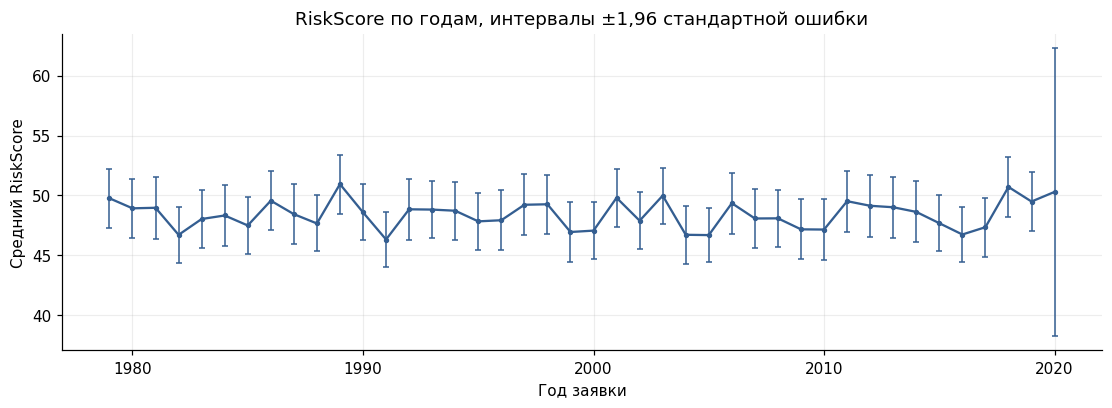

In [3]:
quantiles = [0, .01, .25, .5, .75, .99, 1]
display(development[num_columns + [TARGET]].quantile(quantiles).T.round(4))
display(pd.DataFrame({
    "Уровни на development": {col: ", ".join(sorted(development[col].dropna().unique()))
                              for col in category_columns},
    "Уровни на test": {col: ", ".join(sorted(test[col].unique())) for col in category_columns},
}))
missing_profiles = valid.isna().value_counts().reset_index(name="Строк")
display(missing_profiles[["Строк"] + valid.columns[valid.isna().any()].tolist()])
d = dev_complete
expense_error = d.TotalDebtToIncomeRatio * d.MonthlyIncome - d.MonthlyLoanPayment - d.MonthlyDebtPayments
income_error = d.AnnualIncome / 12 - d.MonthlyIncome
net_error = d.TotalAssets - d.TotalLiabilities - d.NetWorth
np.testing.assert_allclose(expense_error, 0, rtol=0, atol=1e-8)
annuity_rate = d.InterestRate / 12
recovered_amount = d.MonthlyLoanPayment * (-np.expm1(-d.LoanDuration * np.log1p(annuity_rate))) / annuity_rate
annuity_error = (recovered_amount - d.LoanAmount).abs()
np.testing.assert_allclose(recovered_amount, d.LoanAmount, rtol=0, atol=1e-7)
relations = pd.Series({
    "Максимальная ошибка тождества ежемесячного долга": expense_error.abs().max(),
    "Максимальная ошибка восстановления LoanAmount": annuity_error.max(),
    "Доля точных совпадений AnnualIncome / 12 и MonthlyIncome": np.isclose(income_error, 0).mean(),
    "Доля точных совпадений TotalAssets − TotalLiabilities и NetWorth": np.isclose(net_error, 0).mean(),
})
display(relations.to_frame("Результат на development"))
plt.figure(figsize=(10, 3.6), layout="constrained")
year_data = development.assign(Year=pd.to_datetime(development.ApplicationDate).dt.year)
annual = year_data.groupby("Year")[TARGET].agg(["mean", "size", "sem"])
plt.errorbar(annual.index, annual["mean"], yerr=1.96 * annual["sem"], color="#345e91",
             marker=".", markersize=5, elinewidth=1, capsize=2)
plt.xlabel("Год заявки")
plt.ylabel("Средний RiskScore")
plt.title("RiskScore по годам, интервалы ±1,96 стандартной ошибки")
plt.show()

У 456 заявок пропущены одни и те же девять признаков. Ежемесячный долг $D$ нахожу по общей долговой нагрузке $r$, месячному доходу $I$ и платежу по кредиту $P$.

$$
D=rI-P.
$$

Сумму кредита $A$ восстанавливаю по платежу $P$, месячной ставке $i$ и сроку $T$ в месяцах.

$$
A=P\,\frac{1-(1+i)^{-T}}{i},\qquad A=PT\quad\text{при }i=0.
$$

Сверяю обе формулы с заявками без пропусков. Годовой доход, делённый на 12, совпадает с месячным лишь у части заявок. Так же ведёт себя разность активов и обязательств при сравнении с капиталом. Поэтому для остальных пропусков сравниваю заполнение медианой или модой и добавление индикатора пропуска. В тестовом файле все признаки заполнены.

## 2. Разведочный анализ (EDA)

Начинаю с гистограммы `RiskScore`. Два пика помогают понять, почему одной прямой по исходным признакам может не хватить.

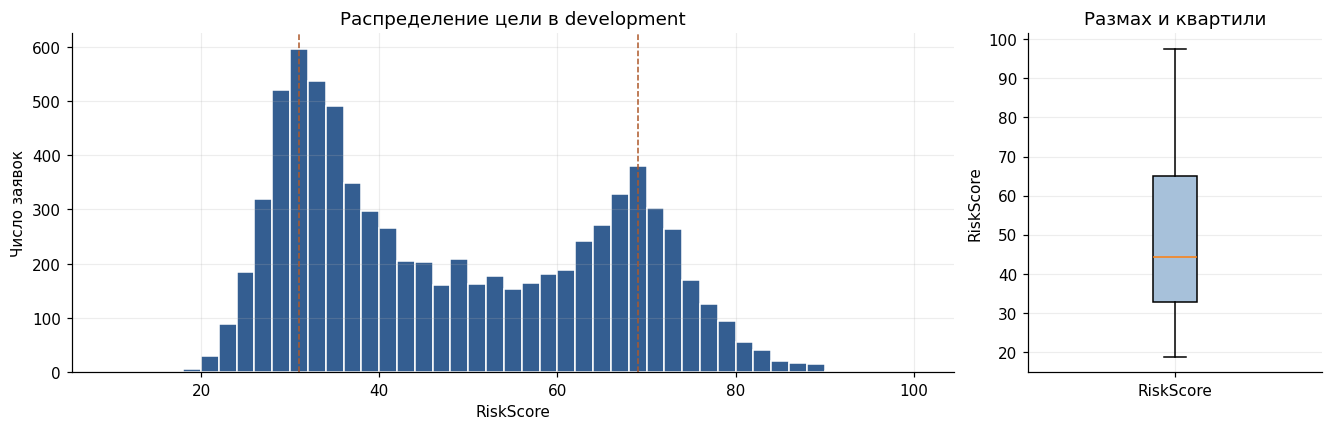

На гистограмме с шагом 2 наиболее частые интервалы ниже и выше 50 центрированы около **31** и **69**. Среднее равно 48.37, медиана 44.21, асимметрия 0.34. Два максимума и правосторонняя асимметрия расходятся с формой нормального распределения.

In [4]:
d = development
hist_target = d[TARGET]
hist_count, hist_edge = np.histogram(hist_target, bins=np.arange(10, 102, 2))
centers = (hist_edge[:-1] + hist_edge[1:]) / 2
low_peak = centers[np.argmax(hist_count * (centers < 50))]
high_peak = centers[np.argmax(hist_count * (centers >= 50))]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained",
                         gridspec_kw={"width_ratios": [3, 1]})
axes[0].hist(hist_target, bins=hist_edge, color="#345e91", edgecolor="white")
for loc in [low_peak, high_peak]:
    axes[0].axvline(loc, linestyle="--", color="#ad582a", linewidth=1)
axes[0].set(title="Распределение цели в development", xlabel="RiskScore", ylabel="Число заявок")
axes[1].boxplot(hist_target, tick_labels=["RiskScore"], patch_artist=True,
                boxprops={"facecolor": "#a7c1da"})
axes[1].set(title="Размах и квартили", ylabel="RiskScore")
plt.show()
display(Markdown(f"На гистограмме с шагом 2 наиболее частые интервалы ниже и выше 50 "
                 f"центрированы около **{low_peak:g}** и **{high_peak:g}**. "
                 f"Среднее равно {hist_target.mean():.2f}, медиана {hist_target.median():.2f}, "
                 f"асимметрия {hist_target.skew():.2f}. "
                 "Два максимума и правосторонняя асимметрия расходятся с формой нормального распределения."))

### Как риск связан с финансовыми признаками

Каждая точка — заявка. Линия соединяет медианы риска по интервалам признака. Там, где значения сильно растянуты вправо, использую логарифмическую ось.

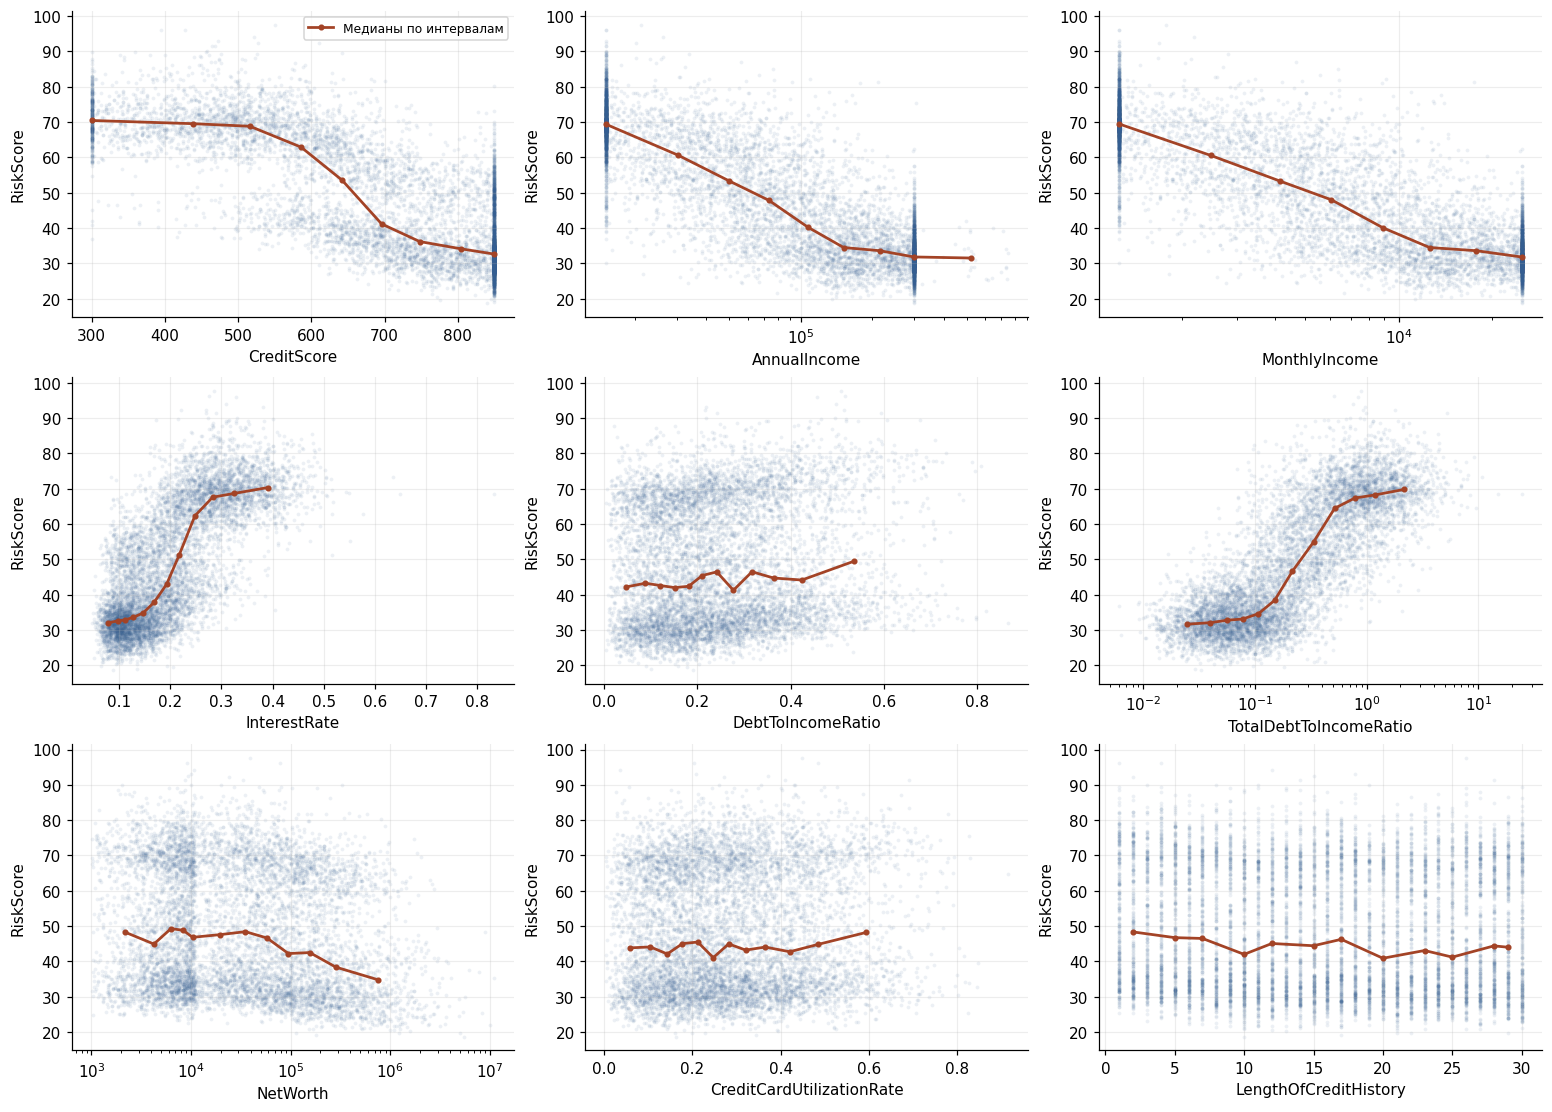

CreditScore                медианы риска по крайним группам:  69.9 и  32.6
AnnualIncome               медианы риска по крайним группам:  69.7 и  31.8
MonthlyIncome              медианы риска по крайним группам:  69.7 и  31.8
InterestRate               медианы риска по крайним группам:  32.3 и  69.4
DebtToIncomeRatio          медианы риска по крайним группам:  42.9 и  46.4
TotalDebtToIncomeRatio     медианы риска по крайним группам:  31.9 и  69.0
NetWorth                   медианы риска по крайним группам:  47.1 и  37.0


In [5]:
eda_features = {
    "CreditScore": False, "AnnualIncome": True, "MonthlyIncome": True,
    "InterestRate": False, "DebtToIncomeRatio": False, "TotalDebtToIncomeRatio": True,
    "NetWorth": True, "CreditCardUtilizationRate": False,
    "LengthOfCreditHistory": False,
}
fig, axes = plt.subplots(3, 3, figsize=(14, 10), layout="constrained")
for (col, use_log), ax in zip(eda_features.items(), axes.flat):
    view = dev_complete[[col, TARGET]]
    ax.scatter(view[col], view[TARGET], s=6, alpha=.09, color="#345e91", linewidths=0)
    bins = pd.qcut(view[col], q=12, duplicates="drop")
    summary = view.groupby(bins, observed=True)[[col, TARGET]].median()
    ax.plot(summary[col], summary[TARGET], color="#a34326", lw=1.8, marker=".", label="Медианы по интервалам")
    if use_log:
        ax.set_xscale("log")
    ax.set(xlabel=col, ylabel="RiskScore")
axes[0, 0].legend(fontsize=8)
plt.show()
for col in ("CreditScore", "AnnualIncome", "MonthlyIncome", "InterestRate", "DebtToIncomeRatio",
            "TotalDebtToIncomeRatio", "NetWorth"):
    left, right = dev_complete[col].quantile([.2, .8])
    lower = dev_complete.loc[dev_complete[col] <= left, TARGET].median()
    upper = dev_complete.loc[dev_complete[col] >= right, TARGET].median()
    print(f"{col:25s}  медианы риска по крайним группам: {lower:5.1f} и {upper:5.1f}")

Медианный риск ниже у заявок с высоким кредитным рейтингом и доходом. С ростом ставки и долговой нагрузки он повышается. На графиках `DebtToIncomeRatio` и `CreditCardUtilizationRate` заметны ступени, поэтому дальше проверяю признаки с порогами.

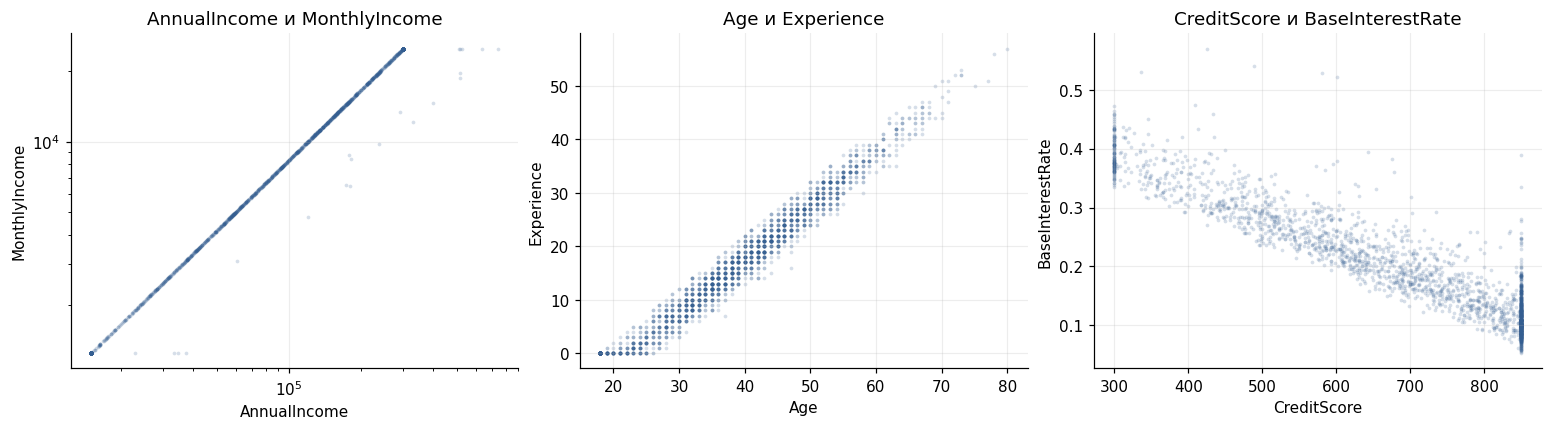

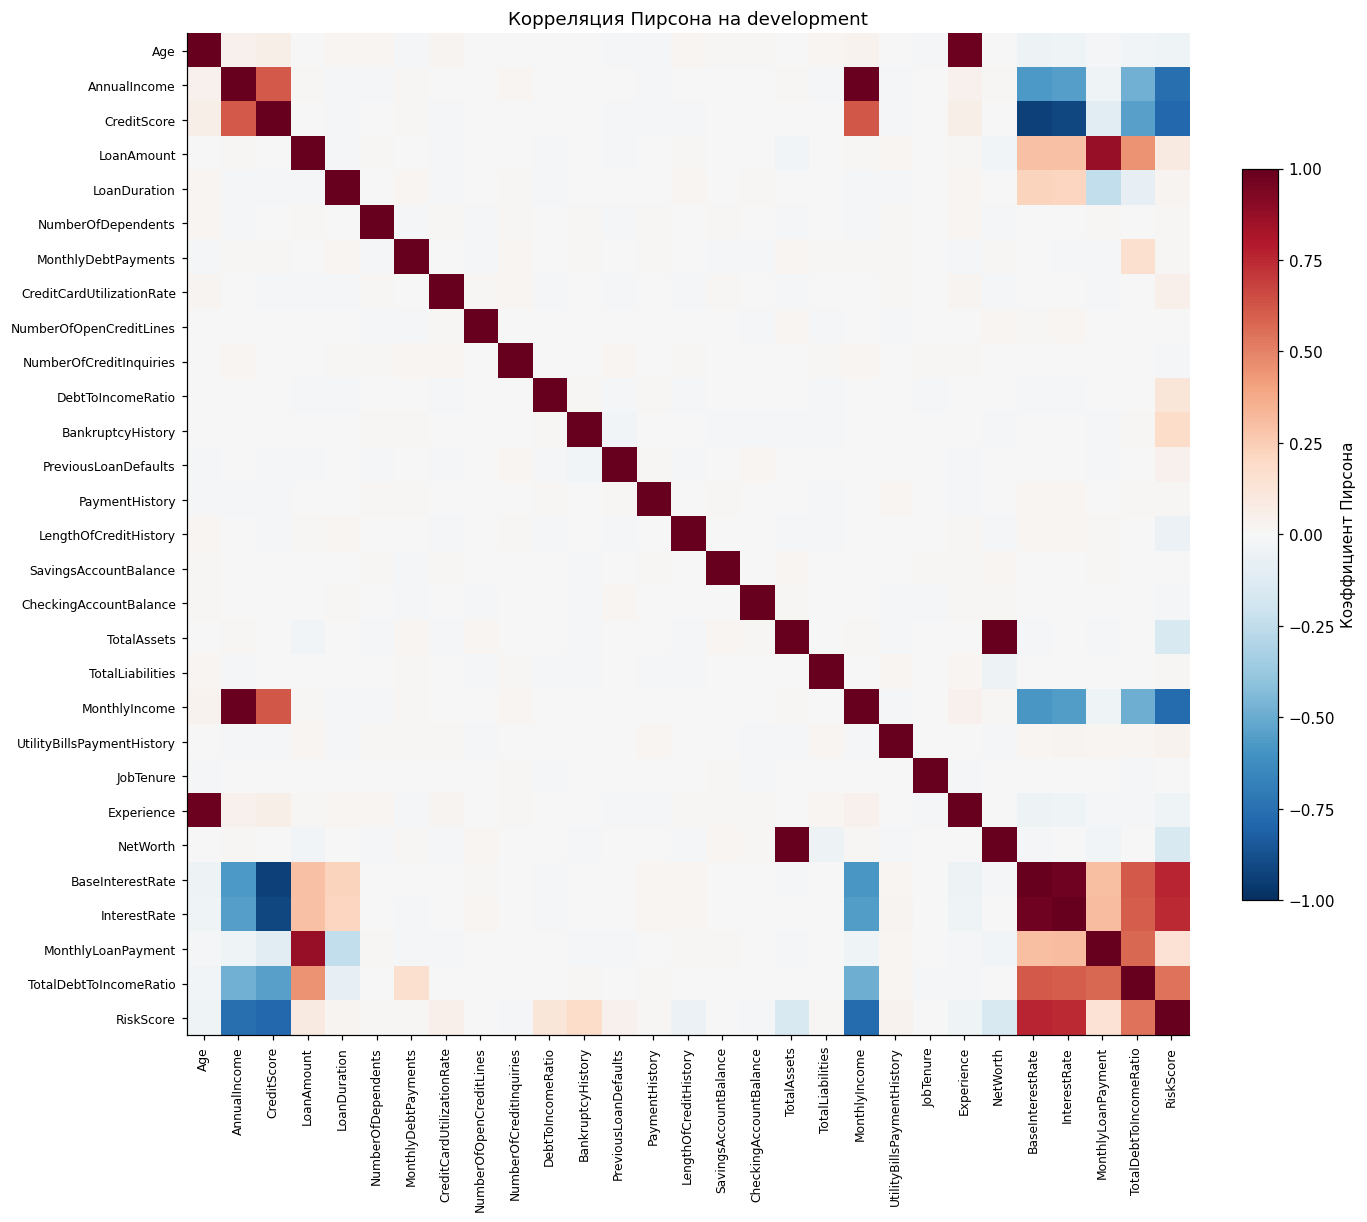

,Корреляция с RiskScore
CreditScore,-0.784
MonthlyIncome,-0.768
BaseInterestRate,0.760
AnnualIncome,-0.757
InterestRate,0.743
TotalDebtToIncomeRatio,0.546
BankruptcyHistory,0.184
TotalAssets,-0.152
NetWorth,-0.151
MonthlyLoanPayment,0.148


Корреляция пары
TotalAssets      NetWorth                      0.993
AnnualIncome     MonthlyIncome                 0.986
Age              Experience                    0.983
BaseInterestRate InterestRate                  0.975
CreditScore      BaseInterestRate             -0.932
                 InterestRate                 -0.908
LoanAmount       MonthlyLoanPayment            0.869
CreditScore      MonthlyIncome                 0.623

size   mean  median
Признак             Категория                              
MaritalStatus       Divorced            1153  47.82   43.07
                    Married             3872  48.64   44.60
                    Single              2391  48.36   44.67
                    Widowed              414  47.42   41.97
HomeOwnershipStatus Mortgage            3078  48.07   43.64
                    Other                807  48.69   45.04
                    Own                 1558  48.75   44.40
                    Rent                2387  48.40   44.67
LoanPurpose         Auto                1536  48.32   45.09
                    Debt Consolidation  1800  48.21   43.84
                    Education           1229  49.44   45.35
                    Home                2227  47.70   42.40
                    Other                681  49.14   46.36
                    NaN                  357  48.48   44.51
EmploymentStatus    Employed            6757  48.01   44.05
                    Self-Employed        742  50.18   44.45
                    Unemployed           331  51.66   47.85
EducationLevel      Associate           1526  48.28   44.19
                    Bachelor            2321  48.13   43.55
                    Doctorate            259  45.45   37.09
                    High School         3146  49.12   46.47
                    Master               578  46.83   39.65

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), layout="constrained")
sample = dev_complete.sample(n=2300, random_state=41)
for ax, (first, second, logarithmic) in zip(axes, [
    ("AnnualIncome", "MonthlyIncome", True), ("Age", "Experience", False),
    ("CreditScore", "BaseInterestRate", False),
]):
    ax.scatter(sample[first], sample[second], s=6, alpha=.2, linewidths=0, color="#345e91")
    if logarithmic:
        ax.set_xscale("log")
        ax.set_yscale("log")
    ax.set(xlabel=first, ylabel=second, title=f"{first} и {second}")
plt.show()
corr = development[num_columns + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(12.6, 11), layout="constrained")
mesh = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
ax.set_xticks(np.arange(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(np.arange(len(corr)), corr.columns, fontsize=8)
ax.set_title("Корреляция Пирсона на development")
ax.grid(False)
fig.colorbar(mesh, ax=ax, shrink=.73, label="Коэффициент Пирсона")
plt.show()
risk_corr = corr[TARGET].drop(TARGET).sort_values(key=lambda s: s.abs(), ascending=False)
num_corr = corr.loc[num_columns, num_columns]
upper_triangle = np.triu(np.ones(num_corr.shape, dtype=bool), k=1)
pairs = num_corr.where(upper_triangle).stack().sort_values(key=lambda s: s.abs(), ascending=False)
display(risk_corr.head(10).round(3).to_frame("Корреляция с RiskScore"))
display(pairs.head(8).round(3).to_frame("Корреляция пары"))
category_summary = pd.concat([
    development.groupby(col, dropna=False)[TARGET].agg(["size", "mean", "median"])
    for col in category_columns
], keys=category_columns, names=["Признак", "Категория"])
display(category_summary.round(2))

Годовой и месячный доход, возраст и стаж, а также процентные ставки тесно связаны. Из-за этого коэффициенты МНК могут заметно меняться при почти одинаковых прогнозах. Для МНК использую `lstsq`, а для расширенного набора признаков сравниваю регуляризации. Корреляция сама по себе не показывает, что ставка вызывает изменение риска.

## 3. Масштабирование

**Z-score.** Из значения вычитаю среднее обучающего столбца и делю на его стандартное отклонение.

$$
z=\frac{x-\mu}{s},\qquad
\mu=\frac{1}{n}\sum_{i=1}^{n}x_i,\qquad
s=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i-\mu)^2}.
$$

**Min-max.** Вычитаю минимум и делю на разность максимума и минимума.

$$
x'=\frac{x-x_{\min}}{x_{\max}-x_{\min}}.
$$

У постоянного столбца знаменатель был бы нулевым, поэтому заменяю его единицей. На обучении получается столбец из нулей, а обратное преобразование возвращает константу. Для проверки и теста беру параметры, рассчитанные на обучении.

In [7]:
def numeric_matrix(X):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or min(X.shape) < 1 or not np.isfinite(X).all():
        raise ValueError("Ожидается непустая конечная матрица признаков")
    return X


class ZScoreScaler:
    def fit(self, X):
        X = numeric_matrix(X)
        constant = X.min(axis=0) == X.max(axis=0)
        self.center_ = np.where(constant, X[0], X.mean(axis=0))
        std = X.std(axis=0)
        self.scale_ = np.where(constant | (std == 0), 1.0, std)
        return self

    def transform(self, X):
        X = numeric_matrix(X)
        self._check_width(X)
        return (X - self.center_) / self.scale_

    def _check_width(self, X):
        if not hasattr(self, "center_"):
            raise RuntimeError("Сначала выполните fit")
        if X.shape[1] != len(self.center_):
            raise ValueError("Число столбцов отличается от fit")

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, X):
        X = numeric_matrix(X)
        self._check_width(X)
        return X * self.scale_ + self.center_


class MinMaxScaler(ZScoreScaler):
    def fit(self, X):
        X = numeric_matrix(X)
        self.center_ = X.min(axis=0)
        span = X.max(axis=0) - self.center_
        self.scale_ = np.where(span > 0, span, 1.0)
        return self


scale_demo = np.array([[2, 10, 7], [4, 20, 7], [6, 50, 7], [8, 60, 7]], dtype=float)
scale_validation = np.array([[10, 0, 8]], dtype=float)
for ours, reference in [(ZScoreScaler(), StandardScaler()), (MinMaxScaler(), SkMinMax())]:
    z = ours.fit_transform(scale_demo)
    np.testing.assert_allclose(z, reference.fit_transform(scale_demo), atol=1e-12)
    np.testing.assert_allclose(ours.inverse_transform(z), scale_demo, atol=1e-12)
    val_z = ours.transform(scale_validation)
    np.testing.assert_allclose(val_z, reference.transform(scale_validation), atol=1e-12)
    np.testing.assert_allclose(ours.inverse_transform(val_z), scale_validation, atol=1e-12)
    assert (z[:, -1] == 0).all()
    display(pd.DataFrame(z).round(4).style.set_caption(type(ours).__name__))
print("Обе реализации совпали со sklearn. Обратное преобразование проверено.")

,0,1,2
0,-1.341600,-1.212700,0.000000
1,-0.447200,-0.727600,0.000000
2,0.447200,0.727600,0.000000
3,1.341600,1.212700,0.000000


,0,1,2
0,0.000000,0.000000,0.000000
1,0.333300,0.200000,0.000000
2,0.666700,0.800000,0.000000
3,1.000000,1.000000,0.000000


Обе реализации совпали со sklearn. Обратное преобразование проверено.


## 4. Метрики качества

**MSE** усредняет квадраты ошибок. Большие ошибки влияют на неё сильнее.

$$
\operatorname{MSE}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2.
$$

**MAE** показывает средний размер ошибки в единицах `RiskScore`.

$$
\operatorname{MAE}=\frac{1}{n}\sum_{i=1}^{n}\lvert y_i-\hat y_i\rvert.
$$

**Коэффициент детерминации** сравнивает ошибку модели с ошибкой прогноза средним.

$$
R^2=1-\frac{\sum_{i=1}^{n}(y_i-\hat y_i)^2}{\sum_{i=1}^{n}(y_i-\bar y)^2}.
$$

**MAPE** усредняет абсолютные ошибки относительно истинных значений.

$$
\operatorname{MAPE}=\frac{1}{n}\sum_{i=1}^{n}
\frac{\lvert y_i-\hat y_i\rvert}{\max(\lvert y_i\rvert,\varepsilon)}.
$$

Как и в sklearn, для MAPE использую машинный эпсилон float64, чтобы избежать деления на ноль. В таблицах MAPE записана долей. При постоянной цели $R^2$ равен 1 для точного прогноза и 0 при ошибке. Для одной строки $R^2$ не определён.

In [8]:
def paired_targets(y_true, y_pred):
    actual, predicted = (np.asarray(v, dtype=float) for v in (y_true, y_pred))
    if actual.ndim != 1 or actual.shape != predicted.shape or not actual.size:
        raise ValueError("Нужны два непустых одномерных массива одной длины")
    if not (np.isfinite(actual).all() and np.isfinite(predicted).all()):
        raise ValueError("Метрики требуют конечных значений")
    return actual, predicted


def mse(y_true, y_pred):
    actual, predicted = paired_targets(y_true, y_pred)
    return float(np.mean(np.square(actual - predicted)))


def mae(y_true, y_pred):
    actual, predicted = paired_targets(y_true, y_pred)
    return float(np.mean(np.abs(actual - predicted)))


def r2(y_true, y_pred):
    actual, predicted = paired_targets(y_true, y_pred)
    if len(actual) < 2:
        return np.nan
    rss = np.square(actual - predicted).sum()
    tss = np.square(actual - actual.mean()).sum()
    return float(1 - rss / tss) if tss > 0 else float(rss == 0)


def mape(y_true, y_pred):
    actual, predicted = paired_targets(y_true, y_pred)
    denominator = np.maximum(np.abs(actual), np.finfo(float).eps)
    return float(np.mean(np.abs(actual - predicted) / denominator))


METRICS = {"MSE": mse, "MAE": mae, "R²": r2, "MAPE": mape}


def evaluate(y, prediction):
    return {name: fn(y, prediction) for name, fn in METRICS.items()}


def expect_value_error(fn, *args):
    try:
        fn(*args)
    except ValueError:
        return
    raise AssertionError(f"{fn.__name__}: ожидался ValueError")


metric_cases = {
    "Обычный прогноз": ([1, -2, 4], [2, -3, 5]),
    "Идеальный прогноз": ([1, -2, 4], [1, -2, 4]),
    "Постоянная цель": ([4, 4, 4], [5, 4, 4]),
    "Постоянная цель, точный прогноз": ([4, 4, 4], [4, 4, 4]),
    "Ноль в цели": ([0, 1, 4], [1, 1, 3]),
}
metric_refs = [mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error]
metric_rows = {}
for label, (actual, prediction) in metric_cases.items():
    metric_rows[label] = evaluate(actual, prediction)
    for metric, reference in zip(METRICS.values(), metric_refs):
        np.testing.assert_allclose(metric(actual, prediction), reference(actual, prediction))
        expect_value_error(metric, [1, 2], [1])
        expect_value_error(metric, [[1], [2]], [1, 2])
        expect_value_error(metric, [], [])
        expect_value_error(metric, [np.nan], [1])
assert np.isnan(r2([1], [1]))
display(pd.DataFrame(metric_rows).T)

,MSE,MAE,R²,MAPE
Обычный прогноз,1.000000,1.000000,0.833333,5.833333e-01
Идеальный прогноз,0.000000,0.000000,1.000000,0.000000e+00
Постоянная цель,0.333333,0.333333,0.000000,8.333333e-02
"Постоянная цель, точный прогноз",0.000000,0.000000,1.000000,0.000000e+00
Ноль в цели,0.666667,0.666667,0.769231,1.501200e+15


## 5. Линейная регрессия

Модель умножает матрицу признаков $X$ на веса $w$ и прибавляет свободный член $b$. Ошибку считаю по MSE.

$$
\hat y=b\mathbf{1}+Xw,\qquad
J(w,b)=\frac{1}{n}\lVert y-\hat y\rVert_2^2.
$$

**Аналитическое решение.** Приравниваю производную по $b$ к нулю и получаю $b=\bar y-\bar Xw$. Затем центрирую признаки и цель и записываю градиент по весам.

$$
\nabla_w J=\frac{2}{n}X_c^\top(X_cw-y_c).
$$

$$
X_c^\top X_c w=X_c^\top y_c.
$$

`lstsq` решает задачу по матрице $X_c$ и подходит даже при зависимых столбцах.

**Градиентный спуск (GD).** На каждом шаге считаю градиент по всем обучающим строкам.

$$
w_{t+1}=w_t-\eta\nabla_w J(w_t).
$$

**Стохастический спуск (SGD).** В начале эпохи перемешиваю строки. Градиент считаю по мини-батчу $B_t$. Шаг уменьшается с номером эпохи $e$.

$$
w_{t+1}=w_t-\eta_e\frac{2}{\lvert B_t\rvert}
X_{B_t}^\top(X_{B_t}w_t-y_{B_t}).
$$

$$
\eta_e=\frac{\eta_0}{\sqrt{1+e/10}}.
$$

Здесь записаны шаги для МНК. Штрафы разбираю в разделе 7. История ошибки позволяет сравнить, как сходятся оба метода.

In [9]:
class LinearRegression:
    def __init__(self, method="analytic", learning_rate=None, max_iter=500, tol=1e-8,
                 random_state=42, fit_intercept=True, batch_size=64, penalty=None,
                 alpha=0.0, l1_ratio=0.5, p=1.5):
        if method not in {"analytic", "gd", "sgd"}:
            raise ValueError("Допустимые методы: analytic, gd, sgd")
        if penalty not in {None, "l1", "l2", "elasticnet", "lp"}:
            raise ValueError("Неизвестный штраф")
        if not np.isfinite(alpha) or alpha < 0 or not 0 <= l1_ratio <= 1:
            raise ValueError("Нужны alpha >= 0 и 0 <= l1_ratio <= 1")
        if not np.isfinite(p) or p < 1:
            raise ValueError("Реализованы конечные p >= 1")
        if (not isinstance(max_iter, (int, np.integer)) or not isinstance(batch_size, (int, np.integer))
                or max_iter < 1 or batch_size < 1 or not np.isfinite(tol) or tol < 0):
            raise ValueError("Проверьте число итераций, размер батча и tol")
        if learning_rate is not None and (not np.isfinite(learning_rate) or learning_rate <= 0):
            raise ValueError("Шаг должен быть положительным и конечным")
        self.method, self.learning_rate, self.max_iter = method, learning_rate, max_iter
        self.tol, self.random_state, self.fit_intercept = tol, random_state, fit_intercept
        self.batch_size, self.p = batch_size, p
        self.l1 = alpha if penalty == "l1" or (penalty == "lp" and p == 1) else 0.0
        self.l2 = alpha if penalty == "l2" or (penalty == "lp" and p == 2) else 0.0
        self.lp = alpha if penalty == "lp" and p not in (1, 2) else 0.0
        if penalty == "elasticnet":
            self.l1, self.l2 = alpha * l1_ratio, alpha * (1 - l1_ratio)

    def _loss(self, X, y, w):
        value = mse(y, X @ w) + self.l1 * np.abs(w).sum() + self.l2 * (w @ w)
        if self.lp:
            value += self.lp * np.power(np.abs(w), self.p).sum()
        return float(value)

    def _gradient(self, X, y, w):
        return 2 * (X.T @ (X @ w - y) / len(X) + self.l2 * w)

    def _prox(self, proposal, step):
        if self.l1:
            return np.sign(proposal) * np.maximum(np.abs(proposal) - step * self.l1, 0)
        if self.lp:
            magnitude = np.abs(proposal)
            lower, upper = np.zeros_like(magnitude), magnitude.copy()
            for _ in range(40):
                middle = (lower + upper) / 2
                left_side = middle + step * self.lp * self.p * middle ** (self.p - 1)
                root_is_higher = left_side < magnitude
                lower = np.where(root_is_higher, middle, lower)
                upper = np.where(root_is_higher, upper, middle)
            return np.sign(proposal) * (lower + upper) / 2
        return proposal

    def fit(self, X, y):
        X = numeric_matrix(X)
        y = np.asarray(y, dtype=float)
        if y.shape != (len(X),) or not np.isfinite(y).all():
            raise ValueError("Цель должна быть конечным одномерным массивом длины len(X)")
        x_mean = X.mean(axis=0) if self.fit_intercept else np.zeros(X.shape[1])
        y_mean = y.mean() if self.fit_intercept else 0.0
        X, y = X - x_mean, y - y_mean
        w = np.zeros(X.shape[1])
        self.converged_ = False
        self.status_ = "Лимит итераций"
        self.loss_history_ = [self._loss(X, y, w)]
        if self.method == "analytic":
            if self.l1 or self.lp:
                raise ValueError("Для этого штрафа используйте итерационный метод")
            if self.l2:
                gram = X.T @ X / len(X) + self.l2 * np.eye(X.shape[1])
                w = solve(gram, X.T @ y / len(X), assume_a="pos")
            else:
                w = np.linalg.lstsq(X, y, rcond=None)[0]
            self.loss_history_.append(self._loss(X, y, w))
            self.converged_, self.status_ = True, "Аналитическое решение"
        else:
            rng = np.random.default_rng(self.random_state)
            step = self.learning_rate
            if self.method == "gd" or step is None:
                gram = X.T @ X / len(X)
            if self.method == "gd":
                rhs = X.T @ y / len(X)
                target_energy = y @ y / len(y)

                def full_gradient(v):
                    return 2 * (gram @ v - rhs + self.l2 * v)

                def full_loss(v):
                    value = max(0., target_energy + v @ (gram @ v - 2 * rhs))
                    value += self.l1 * np.abs(v).sum() + self.l2 * (v @ v)
                    if self.lp:
                        value += self.lp * (np.abs(v) ** self.p).sum()
                    return value

            if step is None:
                lipschitz = 2 * (np.linalg.eigvalsh(gram)[-1] + self.l2)
                step = 1 / max(lipschitz, 1e-12)
                if self.method == "sgd":
                    step *= 0.5
            momentum_point = w.copy()
            momentum = 1.0
            for epoch in range(self.max_iter):
                if self.method == "gd":
                    candidate = self._prox(momentum_point - step * full_gradient(momentum_point), step)
                    accelerated = bool(self.l1 or self.lp)
                    if (accelerated and np.max(np.abs(candidate)) < 1e100
                            and full_loss(candidate) > self.loss_history_[-1]):
                        momentum = 1.0
                        candidate = self._prox(w - step * full_gradient(w), step)
                    new_momentum = (1 + np.sqrt(1 + 4 * momentum ** 2)) / 2 if accelerated else 1.0
                    momentum_point = candidate + (momentum - 1) / new_momentum * (candidate - w)
                    momentum = new_momentum
                else:
                    order = rng.permutation(len(X))
                    eta = step / np.sqrt(1 + epoch / 10)
                    candidate = w.copy()
                    for start in range(0, len(X), self.batch_size):
                        idx = order[start:start + self.batch_size]
                        candidate = self._prox(candidate - eta * self._gradient(X[idx], y[idx], candidate), eta)
                        if not np.isfinite(candidate).all() or np.max(np.abs(candidate)) > 1e100:
                            break
                if not np.isfinite(candidate).all() or np.max(np.abs(candidate)) > 1e100:
                    self.status_ = "Расходимость"
                    break
                current_loss = full_loss(candidate) if self.method == "gd" else self._loss(X, y, candidate)
                self.loss_history_.append(current_loss)
                if current_loss > self.loss_history_[0] * 1e6 + 1:
                    self.status_ = "Расходимость"
                    break
                update = np.linalg.norm(candidate - w)
                w = candidate
                if self.method == "gd" and update <= self.tol * (1 + np.linalg.norm(w)):
                    self.converged_, self.status_ = True, "Малое изменение коэффициентов"
                    break
        self.coef_ = w
        self.intercept_ = float(y_mean - x_mean @ w)
        self.n_iter_ = len(self.loss_history_) - 1
        return self

    def predict(self, X):
        if not hasattr(self, "coef_"):
            raise RuntimeError("Сначала выполните fit")
        X = numeric_matrix(X)
        if X.shape[1] != len(self.coef_):
            raise ValueError("Число признаков отличается от fit")
        return self.intercept_ + X @ self.coef_

### Шаг обучения и сходимость

Сравниваю несколько шагов GD, затем смотрю, как масштабирование влияет на GD и SGD. Для GD заранее считаю $G=X_c^\top X_c/n$ и $q=X_c^\top y_c/n$, чтобы на каждом шаге вычислять градиент МНК как $2(Gw-q)$. При автоматическом выборе шаг равен $1/L$, где

$$
L=2\lambda_{\max}(G+\lambda_2 I).
$$

Для L1 и общего Lp использую ускорение Нестерова. Если ускоренный шаг увеличивает ошибку со штрафом, повторяю шаг от текущих весов.

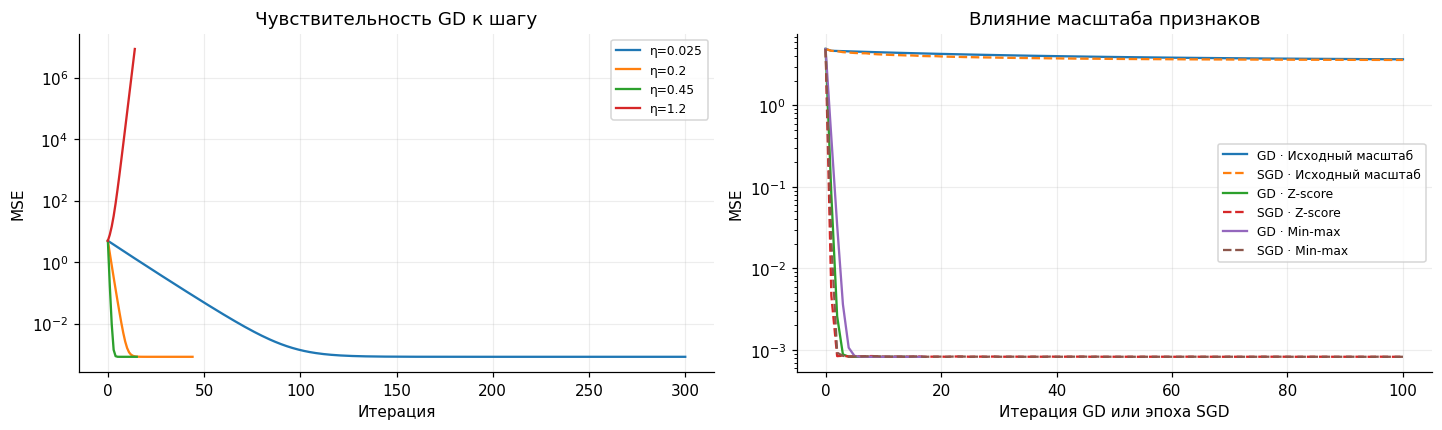

,Шаг,Итерации,Остановка,MSE возвращённой модели
0,0.025,300,Лимит итераций,8.239760e-04
1,0.200,44,Малое изменение коэффициентов,8.239759e-04
2,0.450,15,Малое изменение коэффициентов,8.239759e-04
3,1.200,14,Расходимость,2.635908e+06


Проверены численный градиент, интерфейс fit/predict, остановка и воспроизводимость SGD.


In [10]:
rng = np.random.default_rng(39)
toy_x = rng.normal(size=(360, 5))
toy_y = 5 + toy_x @ np.array([2, -1, 0, .6, 0]) + rng.normal(0, .03, len(toy_x))
xg, yg = toy_x - toy_x.mean(0), toy_y - toy_y.mean()
probe_w = rng.normal(size=5)
gradient_model = LinearRegression(penalty="l2", alpha=.13)
basis = np.eye(len(probe_w)) * 1e-6
numerical_gradient = np.array([
    (gradient_model._loss(xg, yg, probe_w + v) - gradient_model._loss(xg, yg, probe_w - v)) / (2e-6)
    for v in basis
])
np.testing.assert_allclose(gradient_model._gradient(xg, yg, probe_w), numerical_gradient, atol=1e-8)
expect_value_error(LinearRegression().fit, toy_x, toy_y[:, None])

optimum = LinearRegression()
assert optimum.fit(toy_x, toy_y) is optimum
assert optimum.predict(toy_x[:3]).shape == (3,)
sgd_config = dict(method="sgd", learning_rate=.07, max_iter=180, random_state=12)
first_sgd = LinearRegression(**sgd_config).fit(toy_x, toy_y)
second_sgd = LinearRegression(**sgd_config).fit(toy_x, toy_y)
np.testing.assert_array_equal(first_sgd.coef_, second_sgd.coef_)
assert mse(toy_y, first_sgd.predict(toy_x)) < 1.15 * mse(toy_y, optimum.predict(toy_x))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained")
rate_rows = []
for rate in [.025, .2, .45, 1.2]:
    model = LinearRegression(method="gd", learning_rate=rate, max_iter=300).fit(toy_x, toy_y)
    rate_rows.append((rate, model.n_iter_, model.status_, mse(toy_y, model.predict(toy_x))))
    axes[0].semilogy(model.loss_history_, label=f"η={rate:g}")
assert model.status_ == "Расходимость"
assert rate_rows[1][2] == "Малое изменение коэффициентов"
uneven = toy_x * [1, 1e3, 1e2, 1e4, 1e-2]
for label, matrix in [
    ("Исходный масштаб", uneven),
    ("Z-score", ZScoreScaler().fit_transform(uneven)),
    ("Min-max", MinMaxScaler().fit_transform(uneven)),
]:
    for method, style in [("gd", "-"), ("sgd", "--")]:
        model = LinearRegression(method=method, max_iter=100, random_state=12).fit(matrix, toy_y)
        axes[1].semilogy(model.loss_history_, style, label=f"{method.upper()} · {label}")
axes[0].set(title="Чувствительность GD к шагу", xlabel="Итерация", ylabel="MSE")
axes[1].set(title="Влияние масштаба признаков", xlabel="Итерация GD или эпоха SGD", ylabel="MSE")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()
display(pd.DataFrame(rate_rows, columns=["Шаг", "Итерации", "Остановка", "MSE возвращённой модели"]))
print("Проверены численный градиент, интерфейс fit/predict, остановка и воспроизводимость SGD.")

## 6. K-fold и leave-one-out

**K-fold.** Делю данные на части. При делении $n=qk+r$ первые $r$ фолдов получают по $q+1$ строк, остальные — по $q$. Каждый фолд один раз служит проверкой, а модель обучается на остальных.

**Leave-one-out (LOO).** Каждый раз оставляю для проверки только одну строку. В МНК с фиксированными признаками использую PRESS. Здесь $H=U_rU_r^\top$ — матрица проекции, а $U_r$ содержит левые сингулярные векторы, оставшиеся после отсечения численно нулевых направлений. Из обычного остатка $e_i$ и диагонального элемента $h_{ii}$ получаю ошибку при исключении строки.

$$
e_i=y_i-\hat y_i,\qquad
y_i-\hat y_i^{(-i)}=\frac{e_i}{1-h_{ii}}.
$$

Когда $1-h_{ii}$ близко к нулю, обучаю МНК заново без этой строки. PRESS здесь применяю только к МНК с фиксированными признаками и без штрафа.

In [11]:
def kfold_indices(n, k=5, shuffle=True, random_state=42):
    if not isinstance(k, (int, np.integer)) or not isinstance(n, (int, np.integer)) or not 2 <= k <= n:
        raise ValueError("Нужно 2 <= k <= n")
    order = np.arange(n)
    if shuffle:
        np.random.RandomState(random_state).shuffle(order)
    for hold in np.array_split(order, k):
        mask = np.ones(n, dtype=bool)
        mask[hold] = False
        yield np.flatnonzero(mask), np.sort(hold)


def loo_indices(n):
    if not isinstance(n, (int, np.integer)) or n < 2:
        raise ValueError("Для LOO нужно хотя бы два объекта")
    rows = np.arange(n)
    for i in rows:
        yield rows[rows != i], rows[i:i + 1]


def brute_loo(X, y):
    X, y = numeric_matrix(X), np.asarray(y, dtype=float)
    predictions = np.empty(len(X))
    for train_i, val_i in loo_indices(len(X)):
        predictions[val_i] = LinearRegression().fit(X[train_i], y[train_i]).predict(X[val_i])
    return predictions


def press_loo(X, y):
    X, y = numeric_matrix(X), np.asarray(y, dtype=float)
    if len(X) < 2:
        raise ValueError("Для LOO нужно хотя бы два объекта")
    if y.shape != (len(X),) or not np.isfinite(y).all():
        raise ValueError("Для PRESS нужен конечный одномерный y длины len(X)")
    design = np.column_stack((np.ones(len(X)), X - X.mean(0)))
    u, singular, _ = np.linalg.svd(design, full_matrices=False)
    tolerance = singular[0] * max(design.shape) * np.finfo(float).eps
    basis = u[:, singular > tolerance]
    fitted = basis @ (basis.T @ y)
    residuals = y - fitted
    leverage = np.square(basis).sum(axis=1)
    denominator = 1 - leverage
    safe = denominator > 1e-8
    predictions = np.empty(len(X))
    predictions[safe] = y[safe] - residuals[safe] / denominator[safe]
    rows = np.arange(len(X))
    for i in rows[~safe]:
        train_mask = rows != i
        model = LinearRegression().fit(X[train_mask], y[train_mask])
        predictions[i] = model.predict(X[[i]])[0]
    return predictions, int((~safe).sum())


for shuffle in (False, True):
    folds_check = list(kfold_indices(17, 5, shuffle, 7))
    reference = SkKFold(5, shuffle=shuffle, random_state=7 if shuffle else None)
    occurrences = np.zeros(17, dtype=int)
    for (tr, va), (sk_tr, sk_va) in zip(folds_check, reference.split(np.arange(17))):
        assert not np.intersect1d(tr, va).size
        assert len(tr) + len(va) == 17
        np.testing.assert_array_equal(tr, sk_tr)
        np.testing.assert_array_equal(va, sk_va)
        occurrences[va] += 1
    np.testing.assert_array_equal(occurrences, np.ones(17, dtype=int))
    assert [len(va) for _, va in folds_check] == [4, 4, 3, 3, 3]
expect_value_error(list, kfold_indices(4, 5))
expect_value_error(list, loo_indices(1))
for (tr, va), (tr_ref, va_ref) in zip(loo_indices(12), SkLeaveOneOut().split(np.arange(12))):
    np.testing.assert_array_equal(tr, tr_ref)
    np.testing.assert_array_equal(va, va_ref)
for design, target in [
    (toy_x[:16], toy_y[:16]),
    (np.column_stack([toy_x[:16], toy_x[:16, 0], np.ones(16)]), toy_y[:16]),
    (np.eye(5), np.arange(5, dtype=float)),
]:
    predicted = brute_loo(design, target)
    reference = np.array([
        SkLinear().fit(design[tr], target[tr]).predict(design[va])[0]
        for tr, va in SkLeaveOneOut().split(design)
    ])
    np.testing.assert_allclose(predicted, reference, atol=1e-10)
    np.testing.assert_allclose(press_loo(design, target)[0], predicted, atol=1e-10)
assert press_loo(np.eye(5), np.arange(5.))[1] == 5
print("Фолды и LOO совпали со sklearn. PRESS проверен на полном ранге, дублированном столбце и h≈1.")

Фолды и LOO совпали со sklearn. PRESS проверен на полном ранге, дублированном столбце и h≈1.


## 7. Регуляризация

Добавляю к MSE штраф за большие веса. Свободный член оставляю без штрафа.

$$
\begin{aligned}
\Omega_{\mathrm{L1}}(w) &= \lambda_1\lVert w\rVert_1,\\
\Omega_{\mathrm{L2}}(w) &= \lambda_2\lVert w\rVert_2^2,\\
\Omega_{\mathrm{EN}}(w) &= \Omega_{\mathrm{L1}}(w)+\Omega_{\mathrm{L2}}(w),\\
\Omega_{\mathrm{Lp}}(w) &= \lambda_p\sum_j \lvert w_j\rvert^p,\qquad p\ge 1.
\end{aligned}
$$

Для L1 уменьшаю модуль веса с помощью мягкого порога. В аналитическом решении Ridge прибавляю $\lambda_2I$ к матрице Грама. Для общего $p>1$ решаю уравнение для нового модуля веса $u$. Если после градиентного шага получено значение $v$, ищу решение бисекцией на $[0,\lvert v\rvert]$.

$$
\operatorname{soft}(v,\tau)=\operatorname{sign}(v)\max(\lvert v\rvert-\tau,0).
$$

$$
(G+\lambda_2I)w=q.
$$

$$
u+\eta\lambda_p p\,u^{p-1}=\lvert v\rvert.
$$

Проверяю $p=1,\,1.5,\,2,\,3$. При $p=1$ использую ветку L1, а при $p=2$ — L2.

Чтобы сравнить результаты со sklearn при одинаковой силе штрафа, для Lasso беру $\alpha=\lambda_1/2$, а для Ridge — $\alpha=n\lambda_2$. Для Elastic Net задаю $\alpha=\lambda_1/2+\lambda_2$ и `l1_ratio` $=(\lambda_1/2)/\alpha$.

In [12]:
reg_x = ZScoreScaler().fit_transform(toy_x)
reg_y = toy_y
lam = .35
regularization_rows = []
ols_reg = LinearRegression().fit(reg_x, reg_y)
for name, ratio in [("l1", 1.), ("l2", 0.), ("elasticnet", .25), ("elasticnet", .75)]:
    l1, l2 = lam * ratio, lam * (1 - ratio)
    method = "analytic" if name == "l2" else "gd"
    mine = LinearRegression(method=method, penalty=name, alpha=lam, l1_ratio=ratio,
                            tol=1e-10, max_iter=3000).fit(reg_x, reg_y)
    if name == "l2":
        reference = SkRidge(alpha=len(reg_x) * l2)
    elif name == "l1":
        reference = SkLasso(alpha=l1 / 2, tol=1e-12)
    else:
        sk_alpha = l1 / 2 + l2
        reference = SkElastic(alpha=sk_alpha, l1_ratio=(l1 / 2) / sk_alpha, tol=1e-12)
    reference.fit(reg_x, reg_y)
    np.testing.assert_allclose(mine.coef_, reference.coef_, atol=1e-6)
    np.testing.assert_allclose(mine.intercept_, reference.intercept_, atol=1e-10)
    zero_count = np.count_nonzero(mine.coef_ == 0)
    if name == "l1":
        assert zero_count >= 2
    if name == "l2":
        assert np.linalg.norm(mine.coef_) < np.linalg.norm(ols_reg.coef_)
    assert mine.converged_
    regularization_rows.append((name, ratio, np.linalg.norm(mine.coef_), zero_count,
                               np.max(np.abs(mine.coef_ - reference.coef_)), mine.n_iter_))

lp_results = {}
for p in [1., 1.5, 2., 3.]:
    lp_model = LinearRegression(method="gd", penalty="lp", alpha=lam, p=p,
                                max_iter=3000, tol=1e-10).fit(reg_x, reg_y)
    assert lp_model.converged_
    assert lp_model.loss_history_[-1] < lp_model.loss_history_[0]
    if p in (1., 2.):
        paired = LinearRegression(method="gd", penalty=f"l{int(p)}", alpha=lam,
                                  max_iter=3000, tol=1e-10).fit(reg_x, reg_y)
        np.testing.assert_allclose(lp_model.coef_, paired.coef_, atol=1e-9)
    else:
        centered_y = reg_y - reg_y.mean()
        w = lp_model.coef_
        stationarity = 2 * reg_x.T @ (reg_x @ w - centered_y) / len(reg_x)
        stationarity += lam * p * np.sign(w) * np.abs(w) ** (p - 1)
        assert np.max(np.abs(stationarity)) < 1e-6
    lp_results[p] = lp_model.coef_
assert np.linalg.norm(lp_results[1.5] - lp_results[3.]) > .01
expect_value_error(LinearRegression, "gd", None, 500, 1e-8, 42, True, 64, "lp", .2, .5, .5)
display(pd.DataFrame(regularization_rows,
                     columns=["Штраф", "Доля L1", "Норма весов", "Нулевых весов",
                              "Макс. отличие от sklearn", "Итерации"]).round(8))
display(pd.DataFrame(lp_results, index=[f"w{i}" for i in range(reg_x.shape[1])]).round(6))

,Штраф,Доля L1,Норма весов,Нулевых весов,Макс. отличие от sklearn,Итерации
0,l1,1.00,1.949223,2,0.0,12
1,l2,0.00,1.645037,0,0.0,1
2,elasticnet,0.25,1.704830,2,0.0,15
3,elasticnet,0.75,1.854243,2,0.0,15


,1.0,1.5,2.0,3.0
w0,1.711482,1.560234,1.399866,1.171552
w1,-0.848057,-0.793333,-0.763677,-0.745236
w2,-0.000000,-0.000354,-0.003497,-0.004177
w3,0.388715,0.390886,0.404088,0.433120
w4,0.000000,0.000366,0.004577,0.005268


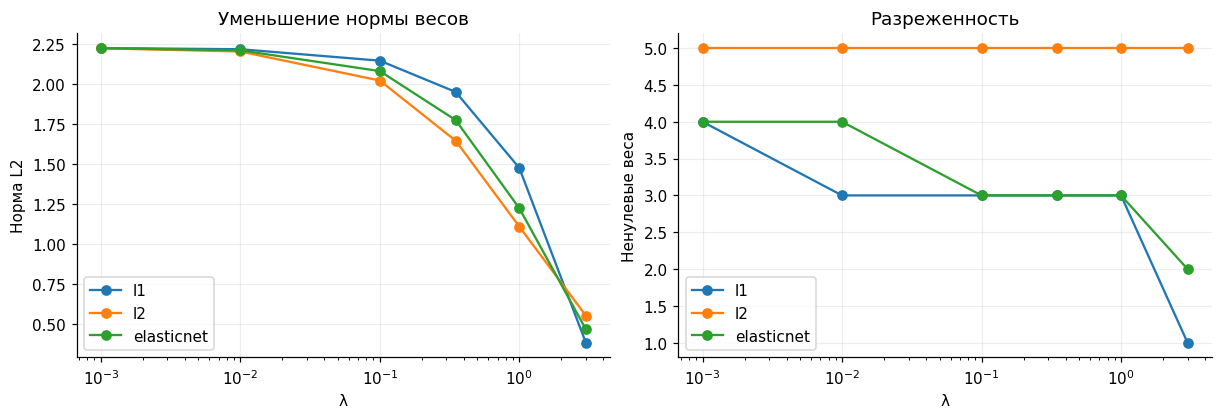

In [13]:
alphas_demo = [.001, .01, .1, .35, 1., 3.]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained")
for name, solver in [("l1", "gd"), ("l2", "analytic"), ("elasticnet", "gd")]:
    counts, norms = [], []
    for strength in alphas_demo:
        trial = LinearRegression(method=solver, penalty=name, alpha=strength,
                                 max_iter=3000, tol=1e-9).fit(reg_x, reg_y)
        assert trial.converged_
        counts.append(np.count_nonzero(trial.coef_))
        norms.append(np.linalg.norm(trial.coef_))
    axes[0].semilogx(alphas_demo, norms, marker="o", label=name)
    axes[1].semilogx(alphas_demo, counts, marker="o", label=name)
axes[0].set(title="Уменьшение нормы весов", xlabel="λ", ylabel="Норма L2")
axes[1].set(title="Разреженность", xlabel="λ", ylabel="Ненулевые веса")
for ax in axes:
    ax.legend()
plt.show()

### 7.1. Проверки на маленьких примерах

Сверяю метрики с ответами, посчитанными вручную. Отдельно проверяю постоянные столбцы, размеры массивов и прогнозы при зависимых признаках. В тесте PRESS проверяю случай, когда исключение одной строки уменьшает ранг матрицы.

In [14]:
def expect_exception(error, function, *args, **kwargs):
    try:
        function(*args, **kwargs)
    except error:
        return
    raise AssertionError(f"{function.__name__}: ожидается {error.__name__}")


for name, scaler in [("z-score", ZScoreScaler), ("min-max", MinMaxScaler)]:
    expect_exception(RuntimeError, scaler().transform, np.ones((1, 2)))
    expect_exception(ValueError, scaler().fit, [[1., np.nan], [2., 3.]])
    fitted = scaler().fit([[2., 7.], [4., 7.]])
    expect_exception(ValueError, fitted.transform, [[np.nan, 7.]])
    expect_exception(ValueError, fitted.transform, [[1.]])
    np.testing.assert_allclose(fitted.inverse_transform(fitted.transform([[6., 8.]])), [[6., 8.]])
    np.testing.assert_allclose(fitted.transform([[2., 7.], [4., 7.]])[:, 1], 0.)

decimal_constant = np.full((1001, 1), .1)
np.testing.assert_array_equal(ZScoreScaler().fit_transform(decimal_constant),
                              np.zeros_like(decimal_constant))
np.testing.assert_allclose(ZScoreScaler().fit(decimal_constant).transform([[.6]]), [[.5]])
np.testing.assert_allclose(ZScoreScaler().fit_transform(decimal_constant),
                           StandardScaler().fit_transform(decimal_constant), atol=1e-15)

actual = [0., -2., 4.]
forecast = [1., -1., 2.]
for fn, result in [(mse, 2.), (mae, 4/3), (r2, 19/28),
                   (mape, (1/np.finfo(float).eps + 1)/3)]:
    np.testing.assert_allclose(fn(actual, forecast), result, rtol=1e-14)
np.testing.assert_allclose(mape([0., 2.], [0., 1.]), .25)
np.testing.assert_allclose([r2([5., 5.], [5., 5.]), r2([5., 5.], [4., 5.])], [1., 0.])

t = np.linspace(-2, 2, 64)
rank_one = np.column_stack([t, t, np.ones(t.size)])
rank_results = []
for intercept, target in [(True, 4 + 2*t), (False, 2*t)]:
    ref = SkLinear(fit_intercept=intercept).fit(rank_one, target)
    for method in ["analytic", "gd", "sgd"]:
        model = LinearRegression(method=method, fit_intercept=intercept, max_iter=450,
                                 batch_size=8, tol=1e-12, random_state=63)
        expect_exception(RuntimeError, model.predict, rank_one)
        model.fit(rank_one, target)
        delta = np.max(np.abs(model.predict(rank_one) - ref.predict(rank_one)))
        assert delta < 1e-7 and np.isfinite(model.coef_).all()
        np.testing.assert_allclose(model.intercept_, 4. if intercept else 0., atol=1e-10)
        expect_exception(ValueError, model.predict, rank_one[:, :2])
        expect_exception(ValueError, model.fit, rank_one, target[:-1])
        expect_exception(ValueError, model.fit, rank_one, target[:, None])
        rank_results.append((method, intercept, delta))
display(pd.DataFrame(rank_results, columns=["Метод", "Свободный член", "Макс. разница со sklearn"]))

ill = np.column_stack([t, t + 1e-8*np.sin(t), 1e6*np.cos(t)])
ill_target = 2 + 1.5*t + .4*np.cos(t)
ill_pred = LinearRegression().fit(ill, ill_target).predict(ill)
np.testing.assert_allclose(ill_pred, SkLinear().fit(ill, ill_target).predict(ill), atol=1e-8)
np.testing.assert_allclose(ill_pred, ill_target, atol=1e-8)

for n_check in range(2, 15):
    for k_check in range(2, n_check + 1):
        ours = list(kfold_indices(n_check, k_check, True, 71))
        ref = list(SkKFold(k_check, shuffle=True, random_state=71).split(np.arange(n_check)))
        for (tr, va), (tr_ref, va_ref) in zip(ours, ref, strict=True):
            np.testing.assert_array_equal(tr, tr_ref)
            np.testing.assert_array_equal(va, va_ref)
        np.testing.assert_array_equal(np.sort(np.concatenate([v for _, v in ours])),
                                     np.arange(n_check))
expect_exception(ValueError, list, kfold_indices(5, 2.5))
expect_exception(ValueError, list, loo_indices(1))
expect_exception(ValueError, press_loo, rank_one, t[:, None])
expect_exception(ValueError, press_loo, rank_one, np.full(len(rank_one), np.nan))
x_p = np.array([[0., 0.], [1., 0.], [2., 0.], [0., 1.]])
y_p = np.array([1., 2., 3., 9.])
press, fallback_count = press_loo(x_p, y_p)
np.testing.assert_allclose(press, brute_loo(x_p, y_p), atol=1e-10)
assert fallback_count == 1
print("Контрольные числа, формы, вырожденность и PRESS с изменением ранга проверены.")

,Метод,Свободный член,Макс. разница со sklearn
0,analytic,True,0.000000e+00
1,gd,True,8.881784e-16
2,sgd,True,8.881784e-16
3,analytic,False,0.000000e+00
4,gd,False,4.440892e-16
5,sgd,False,4.440892e-16


Контрольные числа, формы, вырожденность и PRESS с изменением ранга проверены.


## 8. Подготовка признаков и базовый МНК

Медианы, моды, список категорий, узлы и параметры масштаба считаю заново на обучающей части каждого фолда. При проверке переиспользую эти значения. У незнакомой категории все её индикаторы one-hot равны нулю. `ID` нужен для выгрузки. Год и месяц с учётом его цикличности проверяю в отдельном варианте.

Сравниваю исходные числовые признаки с логарифмами, изломами и ступенями. Точки излома беру из квантилей обучающей части фолда. Пороги ступеней задаю в коде.

$$
\operatorname{hinge}_t(x)=\max(0,x-t),\qquad
\operatorname{step}_t(x)=\mathbf{1}[x\ge t].
$$

In [15]:
LOG_COLUMNS = {
    "AnnualIncome", "MonthlyIncome", "TotalDebtToIncomeRatio", "NetWorth", "LoanAmount",
    "MonthlyLoanPayment", "MonthlyDebtPayments", "TotalAssets", "TotalLiabilities",
}
HINGE_COLUMNS = [
    "Age", "MonthlyIncome", "CreditScore", "LoanAmount", "InterestRate", "NetWorth",
    "DebtToIncomeRatio", "TotalDebtToIncomeRatio", "PaymentHistory", "MonthlyLoanPayment",
    "CreditCardUtilizationRate", "LengthOfCreditHistory", "Experience", "AnnualIncome",
]
STEP_GRID = {
    "AnnualIncome": [25000, 30000, 40000, 50000, 60000, 80000, 100000, 120000, 150000, 200000],
    "CreditScore": list(range(400, 850, 50)) + [775],
    "DebtToIncomeRatio": [.10, .15, .20, .25, .30, .35, .40, .45, .50, .55, .60, .65],
    "CreditCardUtilizationRate": [.10, .20, .30, .40, .50, .60, .70, .80],
    "LengthOfCreditHistory": list(range(2, 15)),
    "NetWorth": [10000, 25000, 50000, 100000, 250000, 500000, 1000000, 2000000],
}


class LoanFeatures:
    def __init__(self, kind="raw", scaled=True, profile=None, calendar=False, missing="restore"):
        self.kind, self.scaled, self.profile, self.calendar = kind, scaled, profile, calendar
        self.missing = missing

    @staticmethod
    def restore(frame):
        x = frame.loc[:, predictor_columns].copy()
        rate = x.InterestRate / 12
        annuity_factor = -np.expm1(-x.LoanDuration * np.log1p(rate)) / rate.where(rate != 0)
        annuity_factor = annuity_factor.where(rate != 0, x.LoanDuration)
        recovered = x.MonthlyLoanPayment * annuity_factor
        x["LoanAmount"] = x.LoanAmount.fillna(recovered.round())
        recovered_debt = x.TotalDebtToIncomeRatio * x.MonthlyIncome - x.MonthlyLoanPayment
        x["MonthlyDebtPayments"] = x.MonthlyDebtPayments.fillna(recovered_debt.round())
        return x

    def _prepared(self, frame):
        x = (self.restore(frame) if self.missing == "restore"
             else frame.loc[:, predictor_columns].copy())
        x["_missing_block"] = frame["LoanPurpose"].isna().astype(float)
        return x

    def _filled(self, x):
        x = x.assign(**x[num_columns].fillna(self.medians_))
        return x.assign(**{col: x[col].fillna(self.modes_[col]) for col in category_columns})

    @staticmethod
    def _curve_data(x, column):
        values = x[column].to_numpy(dtype=float)
        return np.log1p(np.maximum(values, 0)) if column in LOG_COLUMNS else values

    def fit(self, frame):
        x = self._prepared(frame)
        self.medians_ = x[num_columns].median().fillna(0)
        self.modes_ = {col: (x[col].mode().iat[0] if x[col].notna().any() else "")
                       for col in category_columns}
        filled = self._filled(x)
        self.levels_ = {col: sorted(filled[col].unique()) for col in category_columns}
        self.knots_ = {}
        if self.kind in {"smooth", "steps", "projection"}:
            for col in HINGE_COLUMNS:
                self.knots_[col] = np.unique(np.quantile(self._curve_data(filled, col), [.15, .3, .5, .7, .85]))
        matrix = self._design(filled)
        self.names_ = matrix.columns
        self.column_weights_ = np.where(self.names_.str.startswith("Фон:"), .10, 1.)
        self.scaler_ = ZScoreScaler().fit(matrix) if self.scaled else None
        return self

    def _design(self, x):
        if self.kind == "focused":
            basis = focused_features(x, self.profile)
            if self.missing in {"indicator", "restore"}:
                basis["Пропуск кредитного блока"] = x["_missing_block"].to_numpy()
            if self.calendar:
                dates = pd.to_datetime(x.ApplicationDate, format="%Y-%m-%d")
                season = 2*np.pi*(dates.dt.month.to_numpy()-1)/12
                basis.update({"Фон: Год": dates.dt.year.to_numpy(dtype=float),
                              "Фон: Месяц sin": np.sin(season), "Фон: Месяц cos": np.cos(season)})
            return pd.DataFrame(basis, index=x.index)
        basis = {col: x[col].to_numpy(dtype=float) for col in num_columns}
        if self.kind != "raw":
            for col, levels in self.levels_.items():
                for value in levels:
                    basis[f"{col}={value}"] = x[col].fillna("(пропуск)").eq(value).to_numpy(dtype=float)
            if self.missing in {"indicator", "restore"}:
                basis["Пропуск кредитного блока"] = x["_missing_block"].to_numpy()
        if self.calendar:
            dates = pd.to_datetime(x.ApplicationDate, format="%Y-%m-%d", errors="coerce")
            radians = 2 * np.pi * (dates.dt.month.fillna(1).to_numpy() - 1) / 12
            basis.update({"Год": dates.dt.year.fillna(2000).to_numpy(dtype=float),
                          "Месяц sin": np.sin(radians), "Месяц cos": np.cos(radians)})
        for col, knots in self.knots_.items():
            curve = self._curve_data(x, col)
            if col in LOG_COLUMNS:
                basis[f"log1p({col})"] = curve
            for t in knots:
                basis[f"hinge {col} @{t:.10g}"] = np.maximum(curve - t, 0)
        if self.kind in {"steps", "projection"}:
            for col, cuts in STEP_GRID.items():
                for cut in cuts:
                    basis[f"{col} ≥ {cut:g}"] = x[col].ge(cut).to_numpy(dtype=float)
        if self.kind == "projection":
            basis.update(projection_features(x, self.profile))
        return pd.DataFrame(basis, index=x.index)

    def transform(self, frame):
        design = self._design(self._filled(self._prepared(frame)))
        assert design.columns.equals(self.names_)
        matrix = self.scaler_.transform(design) if self.scaler_ else numeric_matrix(design)
        return matrix * self.column_weights_

In [16]:
train_part, val_part = next(kfold_indices(len(dev_complete), 5, random_state=42))
a, b = dev_complete.iloc[train_part], dev_complete.iloc[val_part]
encoder = LoanFeatures(kind="category").fit(a)
comparison_cols = ["Age", "MonthlyIncome", "CreditScore", "TotalDebtToIncomeRatio", "InterestRate",
                   "BankruptcyHistory", "NetWorth", "EmploymentStatus=Employed"]
column_positions = encoder.names_.get_indexer(comparison_cols)
assert (column_positions >= 0).all()
ax, bx = encoder.transform(a)[:, column_positions], encoder.transform(b)[:, column_positions]
ay, by = a[TARGET].to_numpy(), b[TARGET].to_numpy()
models = {
    "Свой МНК": LinearRegression(),
    "sklearn МНК": SkLinear(),
    "Свой GD": LinearRegression(method="gd", max_iter=1500),
    "Свой мини-батч SGD": LinearRegression(method="sgd", max_iter=220, batch_size=128, learning_rate=.04),
    "sklearn SGD": SGDRegressor(penalty=None, max_iter=220, shuffle=True, tol=None, random_state=42,
                                eta0=.005, learning_rate="invscaling", average=True),
}
comparison_rows = {}
reference_prediction = models["sklearn МНК"].fit(ax, ay).predict(bx)
for name, model in models.items():
    started = perf_counter()
    model.fit(ax, ay)
    fit_seconds = perf_counter() - started
    prediction = model.predict(bx)
    comparison_rows[name] = {
        "Train MSE": mse(ay, model.predict(ax)),
        **evaluate(by, prediction),
        "Время fit, с": fit_seconds,
        "RMSE отличия от МНК": np.sqrt(mse(reference_prediction, prediction)),
    }
np.testing.assert_allclose(models["Свой МНК"].predict(bx), reference_prediction, atol=1e-8)
np.testing.assert_allclose(models["Свой GD"].predict(bx), reference_prediction, atol=1e-4)
assert comparison_rows["Свой мини-батч SGD"]["RMSE отличия от МНК"] < 1.5
assert comparison_rows["sklearn SGD"]["RMSE отличия от МНК"] < 1.5
comparison_table = pd.DataFrame(comparison_rows).T
display(comparison_table.round(6))

loo_cols = ["Age", "CreditScore", "MonthlyIncome", "InterestRate", "DebtToIncomeRatio",
            "TotalDebtToIncomeRatio", "NetWorth", "BankruptcyHistory"]
real_x, real_y = dev_complete[loo_cols].to_numpy(), dev_complete[TARGET].to_numpy()
real_loo, fallbacks = press_loo(real_x, real_y)
for i in [0, len(real_x) // 3, len(real_x) - 1]:
    use = np.arange(len(real_x)) != i
    np.testing.assert_allclose(LinearRegression().fit(real_x[use], real_y[use]).predict(real_x[[i]]),
                               real_loo[[i]], atol=1e-7)
real_loo_metrics = evaluate(real_y, real_loo)
display(pd.DataFrame([real_loo_metrics], index=[f"LOO МНК, n={len(real_x)}, явных refit={fallbacks}"]).round(5))

,Train MSE,MSE,MAE,R²,MAPE,"Время fit, с",RMSE отличия от МНК
Свой МНК,57.147810,58.414377,6.175143,0.805232,0.143329,0.002166,0.000000
sklearn МНК,57.147810,58.414377,6.175143,0.805232,0.143329,0.004243,0.000000
Свой GD,57.147810,58.414378,6.175143,0.805232,0.143329,0.064169,0.000001
Свой мини-батч SGD,57.160057,58.327672,6.166509,0.805521,0.143205,1.294583,0.113118
sklearn SGD,57.149828,58.432547,6.179247,0.805171,0.143326,0.406880,0.044232


,MSE,MAE,R²,MAPE
"LOO МНК, n=7473, явных refit=0",54.24648,5.90103,0.81757,0.13829


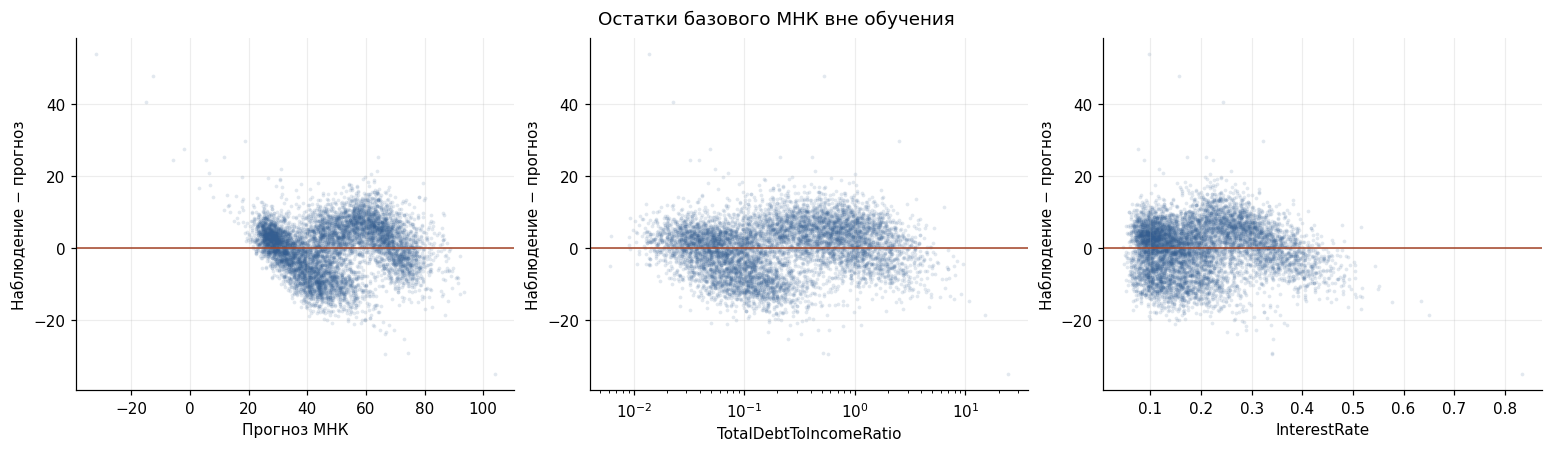

MSE базового МНК по OOF-прогнозам: 51.0582. Разбиения, прогнозы и MSE по фолдам совпали со sklearn.


In [17]:
baseline_oof = np.empty(len(dev_complete))
sk_oof = np.empty(len(dev_complete))
models_kfold = kfold_indices(len(dev_complete), 5, random_state=61)
sk_kfold = SkKFold(5, shuffle=True, random_state=61).split(dev_complete)
for (a_idx, b_idx), (a_ref, b_ref) in zip(models_kfold, sk_kfold, strict=True):
    np.testing.assert_array_equal(a_idx, a_ref)
    np.testing.assert_array_equal(b_idx, b_ref)
    a, b = dev_complete.iloc[a_idx], dev_complete.iloc[b_idx]
    enc = LoanFeatures().fit(a)
    xt, xv, yt = enc.transform(a), enc.transform(b), a[TARGET].to_numpy()
    baseline_oof[b_idx] = LinearRegression().fit(xt, yt).predict(xv)
    sk_oof[b_ref] = SkLinear().fit(xt, yt).predict(xv)
    np.testing.assert_allclose(mse(b[TARGET], baseline_oof[b_idx]),
                               mean_squared_error(b[TARGET], sk_oof[b_ref]), atol=1e-9)
baseline_resid = dev_complete[TARGET].to_numpy() - baseline_oof
np.testing.assert_allclose(baseline_oof, sk_oof, atol=1e-8)
np.testing.assert_allclose(mse(dev_complete[TARGET], baseline_oof),
                           mean_squared_error(dev_complete[TARGET], sk_oof), atol=1e-9)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for ax, x, label, use_log in [
    (axes[0], baseline_oof, "Прогноз МНК", False),
    (axes[1], dev_complete.TotalDebtToIncomeRatio, "TotalDebtToIncomeRatio", True),
    (axes[2], dev_complete.InterestRate, "InterestRate", False),
]:
    ax.scatter(x, baseline_resid, s=6, alpha=.14, linewidths=0, color="#345e91")
    ax.axhline(0, color="#a34326", linewidth=1)
    if use_log:
        ax.set_xscale("log")
    ax.set(xlabel=label, ylabel="Наблюдение − прогноз")
fig.suptitle("Остатки базового МНК вне обучения")
plt.show()
print(f"MSE базового МНК по OOF-прогнозам: {np.mean(baseline_resid ** 2):.4f}. "
      "Разбиения, прогнозы и MSE по фолдам совпали со sklearn.")

У базового МНК остатки образуют две полосы. Дальше добавляю плавные переходы и их произведения с балльным признаком, чтобы точнее описать обе области риска.

## 9. Признаки для Ridge

**Индекс нагрузки.** Складываю признаки заявки $v(x)$ с заданными весами $q$. Доход и капитал снижают индекс, а долговая нагрузка и сумма займа повышают его.

$$
z=v(x)^\top q.
$$

**Плавные переходы.** Меняю вклад отдельных признаков и вычисляю функцию перехода около точек $t$. Параметр $h$ задаёт ширину перехода. Сравниваю $\tanh$ и $\operatorname{erf}$.

$$
a_t(z)=g\!\left(\frac{z-t}{h}\right),
\qquad g\in\{\tanh,\operatorname{erf}\}.
$$

Из каждого перехода получаю два признака. Первый — значение перехода, второй — это значение, умноженное на сумму баллов за финансовые пороги. Вместе со ступенями, изломами и фоновыми признаками они образуют вектор заявки. Модель подбирает один набор весов $w$.

$$
\hat y=b+w^\top\phi(x).
$$

In [18]:
def build_load_index(x, profile):
    def column(name):
        return x[name].to_numpy(dtype=float)

    bankrupt = column("BankruptcyHistory")
    default = column("PreviousLoanDefaults")
    unemployed = x["EmploymentStatus"].eq("Unemployed").to_numpy(dtype=float)
    owner = x["HomeOwnershipStatus"].isin(["Own", "Mortgage"]).to_numpy(dtype=float)
    education = x["EducationLevel"].map(
        {"High School": 0, "Associate": 1, "Bachelor": 2, "Master": 3, "Doctorate": 4}
    ).fillna(0).to_numpy(dtype=float)

    inputs = {
        "общий долг": column("TotalDebtToIncomeRatio"), "ставка": 5 * column("InterestRate"),
        "доход": column("MonthlyIncome") / 10000, "капитал": column("NetWorth") / 500000,
        "банкротство": bankrupt, "дефолт": default, "образование": education,
        "без работы": unemployed, "жильё": owner, "рейтинг": column("CreditScore") / 1000,
        "возраст": column("Age") / 50, "стаж": column("Experience") / 50,
        "платежи": column("PaymentHistory") / 100, "сумма кредита": column("LoanAmount") / 100000,
        "срок": column("LoanDuration") / 100,
    }
    broad_exposure = [1., .65, -.80, -.40, .30, .12, -.10, .10, -.10, .75, -.30, -.10, -.40, .50, 0.]
    affordability = [1., .62, -.94, -.55, .30, .13, -.09, .10, -.12, .96, -.10, -.01, -.50, .70, 0.]
    perturb = [0., .20, .20, .20, .08, .05, .025, .05, .05, .25, .15, .12, .25, .20, .10]
    coeff = broad_exposure if profile == "wide" else affordability
    if profile.startswith("brace"):
        coeff = (np.array(broad_exposure) + np.array(affordability)) / 2
    z = np.column_stack(list(inputs.values())) @ coeff
    symmetry = list(zip(inputs.items(), perturb))
    if profile == "compact":
        selected_axes = {"ставка", "доход", "капитал", "рейтинг", "сумма кредита"}
        symmetry = [(item, step) for item, step in symmetry if item[0] in selected_axes]
    if profile.startswith("brace"):
        axes = {"ставка", "доход", "капитал", "банкротство", "образование", "жильё",
                "рейтинг", "возраст", "сумма кредита"}
        symmetry = [(item, step) for item, step in symmetry if item[0] in axes]
    directions = {"базовый": z}
    for (name, value), dx in symmetry:
        if dx:
            directions[f"{name} ↓"] = z - dx * value
            directions[f"{name} ↑"] = z + dx * value
    return z, directions


def threshold_points(x):
    bankrupt = x.BankruptcyHistory.to_numpy(dtype=float)
    default = x.PreviousLoanDefaults.to_numpy(dtype=float)
    employed = x.EmploymentStatus.eq("Employed").to_numpy(dtype=float)

    def count_thresholds(column, cuts):
        return np.searchsorted(cuts, x[column].to_numpy(dtype=float), side="right")

    rating = count_thresholds("CreditScore", [600, 650, 700, 750])
    income = count_thresholds("AnnualIncome", [30000, 50000, 80000, 120000])
    reserve = count_thresholds("NetWorth", [50000, 100000, 250000, 500000, 1000000])
    history = count_thresholds("LengthOfCreditHistory", [3, 5, 7, 10])
    debts = count_thresholds("DebtToIncomeRatio", [.2, .3, .4, .5])
    cards = count_thresholds("CreditCardUtilizationRate", [.2, .4, .6])
    points = 10 - .7 * rating - .45 * income - .4 * reserve - .2 * history
    points += .4 * debts + .3 * cards + 2.5 * bankrupt + .55 * default - .6 * employed
    return points


def projection_features(x, profile, return_index=False):
    z, directions = build_load_index(x, profile)
    points = threshold_points(x)
    centers = [-.8, -.5, -.2, 0., .2, .4, .6, .9, 1.2, 1.6]
    width = .26 if profile == "wide" else .17
    activation_fn = np.tanh
    if profile.startswith("brace"):
        activation_fn = erf
        width = .24
        centers = np.linspace(-.65, 1.25, 13 if profile.endswith("13") else 9)
    features = {}
    for direction, projection in directions.items():
        for center in centers:
            activation = activation_fn((projection - center) / width)
            name = f"Переход {direction} @{center:g}"
            features[name] = activation
            features[f"{name} × баллы"] = activation * points
    return (features, z) if return_index else features


CORE_STEPS = {
    "AnnualIncome": [30000, 50000, 80000, 120000],
    "CreditScore": [600, 650, 700, 750],
    "DebtToIncomeRatio": [.2, .3, .4, .5],
    "CreditCardUtilizationRate": [.2, .4, .6],
    "LengthOfCreditHistory": [3, 5, 7, 10],
    "NetWorth": [50000, 100000, 250000, 500000, 1000000],
}


def focused_features(x, profile):
    """Сфокусированный базис. Все нелинейные функции используют только поля заявки."""
    is_brace = profile.startswith("brace")
    base_profile = "detail"
    if is_brace:
        base_profile = "brace13" if profile == "brace-age13" else "brace"
    values, index = projection_features(x, base_profile, return_index=True)
    for col, cuts in CORE_STEPS.items():
        for t in cuts:
            values[f"Ступень {col} ≥ {t:g}"] = x[col].ge(t).to_numpy(dtype=float)
    values["BankruptcyHistory"] = x.BankruptcyHistory.to_numpy()
    values["PreviousLoanDefaults"] = x.PreviousLoanDefaults.to_numpy()
    values["EmploymentStatus=Employed"] = x.EmploymentStatus.eq("Employed").to_numpy(dtype=float)

    if is_brace:
        for col in ["MonthlyIncome", "LoanAmount", "NetWorth", "InterestRate", "Age",
                    "CreditScore", "TotalDebtToIncomeRatio", "BaseInterestRate"]:
            values[f"Фон: {col}"] = x[col].to_numpy()
        for col, cuts in STEP_GRID.items():
            for t in cuts:
                if t not in CORE_STEPS[col]:
                    values[f"Фон: {col} ≥ {t:g}"] = x[col].ge(t).to_numpy(dtype=float)

    if profile in {"focused-age", "brace-age", "brace-age13"}:
        corrections = {
            "старше 50": np.maximum(x.Age.to_numpy()-50, 0)/22,
            "младше 35": np.maximum(35-x.Age.to_numpy(), 0)/18,
            "базовая ставка": 5*x.BaseInterestRate.to_numpy()-1,
            "насыщение долговой нагрузки": np.arctan(x.TotalDebtToIncomeRatio.to_numpy())-.18,
        }
        centers = np.linspace(-.65, 1.25, 9)
        transition, width = (erf, .24) if is_brace else (np.tanh, .18)
        for key, delta in corrections.items():
            for j, knot in enumerate(centers):
                values[f"Локальный переход {key} #{j}"] = transition((index + .20*delta-knot)/width)
    if profile == "brace-ratios":
        ratios = {
            "Кредит / годовой доход": np.log1p(x.LoanAmount / x.AnnualIncome),
            "Платёж / месячный доход": np.log1p(x.MonthlyLoanPayment / x.MonthlyIncome),
            "Кредит / капитал": np.log1p(x.LoanAmount / np.maximum(x.NetWorth, 20000)),
            "Разница ставок": x.InterestRate - x.BaseInterestRate,
        }
        for key, series in ratios.items():
            col = series.to_numpy(dtype=float)
            values[f"Фон: {key}"] = col
            values[f"Фон: ({key})²"] = col**2
            values[f"Фон: локальное {key}"] = col*np.exp(-((index-.2)/.55)**2)
    return values


probe_train = dev_complete.iloc[:100].copy()
probe_test = dev_complete.iloc[100:103].copy()
probe_test["LoanPurpose"] = "test-only category"
probe_test["CreditScore"] = np.nan
encoder = LoanFeatures(kind="steps").fit(probe_train)
medians_before = encoder.medians_.copy()
levels_before = {c: list(values) for c, values in encoder.levels_.items()}
assert probe_test.shape[0] == encoder.transform(probe_test).shape[0]
assert np.isfinite(encoder.transform(probe_test)).all()
pd.testing.assert_series_equal(encoder.medians_, medians_before)
assert encoder.levels_ == levels_before
assert "test-only category" not in encoder.levels_["LoanPurpose"]
assert not any("ID" == name or TARGET == name for name in encoder.names_)
assert encoder.transform(probe_test).shape[1] == encoder.transform(probe_train).shape[1]
print("Подготовка сохраняет схему с новыми категориями и пропусками. Параметры fit остались прежними.")

Подготовка сохраняет схему с новыми категориями и пропусками. Параметры fit остались прежними.


### 9.1. Первая посылка и повторная кросс-валидация

Сравниваю исходную Ridge с сокращёнными наборами признаков. Среди вариантов есть изломы по возрасту, преобразования ставок и финансовых отношений. Фоновые признаки после z-score умножаю на 0,1. Чтобы вклад такого признака в прогноз остался тем же, его вес нужно увеличить в 10 раз. Штраф L2 за этот вклад увеличивается в 100 раз.

Делаю два разбиения на пять фолдов. Каждый раз использую параметры масштаба и заполнения пропусков только из обучающих строк. Если две модели используют один набор признаков, обе получают одну и ту же матрицу. Сравниваю OLS, Ridge, Lasso и Elastic Net, а также варианты обработки пропусков. Основную оценку считаю по заявкам без пропусков.

В модели первой посылки 19 вариантов индекса, 13 узлов и два столбца на переход. Это $19\cdot13\cdot2=494$ признака. Вместе с изломами, ступенями и фоновыми признаками получается 603.

In [19]:
from dataclasses import dataclass


@dataclass(frozen=True)
class Experiment:
    name: str
    kind: str
    alpha: float = 0.
    penalty: str | None = None
    profile: str | None = None
    missing: str = "complete"
    scaled: bool = True
    calendar: bool = False

    def encoder(self):
        mode = "restore" if self.missing in {"complete", "restore"} else self.missing
        return LoanFeatures(kind=self.kind, scaled=self.scaled, profile=self.profile,
                            calendar=self.calendar, missing=mode)

    def model(self):
        method = "gd" if self.penalty in {"l1", "elasticnet"} else "analytic"
        return LinearRegression(method=method, penalty=self.penalty, alpha=self.alpha,
                                max_iter=8500, tol=3e-6)

    @property
    def use_partial(self):
        return self.missing != "complete"

    def features_key(self):
        return (self.kind, self.profile, self.missing, self.scaled, self.calendar)


def focus(name, profile="brace", alpha=.004, penalty="l2", missing="complete"):
    return Experiment(name, "focused", alpha=alpha, penalty=penalty,
                      profile=profile, missing=missing)


raw_spec = Experiment("МНК · числовой", "raw")
legacy = Experiment("Прежняя Ridge · λ=.009", "projection", .009, "l2", "detail")
ridge_common = focus("Ridge · узкие .004")
ridge_age = focus("Ridge · узкие с локальными изломами", "brace-age")
ridge_age13 = focus("Ridge · узкие с локальными изломами, 13 узлов", "brace-age13", .004)
experiments = [
    raw_spec,
    Experiment("МНК · категории", "category"),
    Experiment("МНК · изломы", "smooth"),
    Experiment("Ridge · изломы и ступени", "steps", .003, "l2"),
    legacy,
    focus("Ridge · ключевые ступени", "focused"),
    focus("Ridge · локальные изломы", "focused-age"),
    ridge_common,
    focus("Ridge · узкие .0015", alpha=.0015),
    focus("Ridge · узкие .008", alpha=.008),
    ridge_age,
    focus("Ridge · узкие с локальными изломами, λ=.0015", "brace-age", .0015),
    ridge_age13,
    focus("Ridge · узкие с финансовыми отношениями", "brace-ratios"),
    Experiment("Ridge · узкие с календарём", "focused", .004, "l2", "brace", calendar=True),
    focus("МНК · узкие", alpha=0., penalty=None),
    focus("Lasso · узкие .004", alpha=.004, penalty="l1"),
    focus("Lasso · узкие .012", alpha=.012, penalty="l1"),
    focus("Elastic Net · узкие .004", alpha=.004, penalty="elasticnet"),
    focus("Elastic Net · узкие .012", alpha=.012, penalty="elasticnet"),
    focus("Все заявки · медиана и мода", "brace-age", missing="median"),
    focus("Все заявки · с индикатором", "brace-age", missing="indicator"),
    focus("Все заявки · формулы и индикатор", "brace-age", missing="restore"),
]
by_spec = {spec.name: spec for spec in experiments}
dev_partial = development.loc[development.isna().any(axis=1)].reset_index(drop=True)
assert len(dev_complete) + len(dev_partial) == len(development)
dev_y, partial_y = dev_complete[TARGET].to_numpy(), dev_partial[TARGET].to_numpy()
seeds = (61, 153)
all_results = {spec.name: [] for spec in experiments}
cv_predictions = {spec.name: np.full((len(seeds), len(dev_y)), np.nan) for spec in experiments}
partial_predictions = {spec.name: np.full((len(seeds), len(partial_y)), np.nan) for spec in experiments}
missing_checks = [ridge_age.name] + [s.name for s in experiments if s.use_partial]


def fit_experiment(spec, training_rows):
    encoder = spec.encoder().fit(training_rows)
    model = spec.model().fit(encoder.transform(training_rows), training_rows[TARGET].to_numpy())
    return encoder, model


def compare_folds(complete_rows, partial_rows, folds, seed, specs, check_partial=True):
    complete_folds = kfold_indices(len(complete_rows), folds, random_state=seed)
    partial_folds = kfold_indices(len(partial_rows), folds, random_state=seed)
    for (train_idx, val_idx), (extra_train, extra_val) in zip(complete_folds, partial_folds, strict=True):
        train = complete_rows.iloc[train_idx]
        val = complete_rows.iloc[val_idx]
        val_partial = partial_rows.iloc[extra_val]
        train_augmented = pd.concat([train, partial_rows.iloc[extra_train]])
        validation_dates = pd.concat([val, val_partial]).ApplicationDate
        assert not set(train_augmented.ApplicationDate).intersection(validation_dates)

        cache = {}
        for spec in specs:
            key = spec.features_key()
            if key not in cache:
                source = train_augmented if spec.use_partial else train
                encoder = spec.encoder().fit(source)
                cache[key] = (
                    encoder, encoder.transform(source), encoder.transform(val), source[TARGET].to_numpy()
                )
            encoder, x_train, x_val, y_train = cache[key]
            model = spec.model().fit(x_train, y_train)
            prediction = model.predict(x_val)
            prediction_partial = None
            if check_partial and spec.name in missing_checks:
                prediction_partial = model.predict(encoder.transform(val_partial))
            yield (spec, val_idx, prediction, extra_val, prediction_partial,
                   x_train.shape[1], model.converged_)


for rep, seed in enumerate(seeds):
    for spec, va, pred, ev, pp, width, converged in compare_folds(dev_complete, dev_partial, 5, seed, experiments):
        name = spec.name
        assert np.isnan(cv_predictions[name][rep, va]).all()
        cv_predictions[name][rep, va] = pred
        if pp is not None:
            assert np.isnan(partial_predictions[name][rep, ev]).all()
            partial_predictions[name][rep, ev] = pp
        all_results[name].append((mse(dev_y[va], pred), width, converged))

scores_rows = {}
for name, preds in cv_predictions.items():
    assert np.isfinite(preds).all()
    fold_mse, widths, finished = map(np.asarray, zip(*all_results[name], strict=True))
    scores_rows[name] = {
        "Столбцов": int(np.median(widths)),
        "λ": by_spec[name].alpha,
        **evaluate(np.tile(dev_y, len(seeds)), preds.ravel()),
        "SD MSE": fold_mse.std(ddof=1),
        "Мин. MSE": fold_mse.min(),
        "Макс. MSE": fold_mse.max(),
        "Fit до критерия": int(finished.sum()),
    }
scores = pd.DataFrame(scores_rows).T.sort_values("MSE")
display(Markdown("**Метрики и число признаков**"))
display(scores[["Столбцов", "λ", "MSE", "MAE", "R²", "MAPE"]].round(5))
display(Markdown("**Разброс MSE по 10 фолдам**"))
display(scores[["SD MSE", "Мин. MSE", "Макс. MSE", "Fit до критерия"]].round(5))
winner = scores.index[0]
selected = by_spec[winner]
print(f"Выбрано до проверки holdout: {winner}")

paired = []
for rep, seed in enumerate(seeds):
    for i, (_, va) in enumerate(kfold_indices(len(dev_y), 5, random_state=seed), start=1):
        current = mse(dev_y[va], cv_predictions[winner][rep, va])
        prev = mse(dev_y[va], cv_predictions[legacy.name][rep, va])
        paired.append((seed, i, current, prev, current-prev))
repeat_table = pd.DataFrame(paired, columns=["Seed", "Фолд", "Итоговая MSE", "Прежняя MSE", "Разница"])
display(repeat_table.round(5))
display(repeat_table.groupby("Seed")[["Итоговая MSE", "Прежняя MSE", "Разница"]].mean().round(5))

missing_table = pd.DataFrame({
    name: {"MSE на полных": scores.loc[name, "MSE"],
           "MSE на неполных": mse(np.tile(partial_y, len(seeds)), partial_predictions[name].ravel())}
    for name in missing_checks
}).T
display(missing_table.round(5))
assert scores.loc["Ridge · узкие с календарём", "Столбцов"] == scores.loc[ridge_common.name, "Столбцов"] + 3

**Метрики и число признаков**

,Столбцов,λ,MSE,MAE,R²,MAPE
"Ridge · узкие с локальными изломами, 13 узлов",603.0,0.0040,18.57315,3.02048,0.93754,0.06985
Ridge · узкие с локальными изломами,451.0,0.0040,18.58560,3.02239,0.93750,0.06990
"Ridge · узкие с локальными изломами, λ=.0015",451.0,0.0015,18.59692,3.02182,0.93746,0.06988
Ridge · локальные изломы,644.0,0.0040,18.60767,3.01403,0.93742,0.06970
Ridge · узкие с финансовыми отношениями,427.0,0.0040,18.62923,3.02592,0.93735,0.06999
Elastic Net · узкие .004,415.0,0.0040,18.66488,3.02443,0.93723,0.06994
Ridge · узкие .004,415.0,0.0040,18.66614,3.02684,0.93723,0.06999
Ridge · узкие с календарём,418.0,0.0040,18.66941,3.02808,0.93721,0.07001
Ridge · узкие .0015,415.0,0.0015,18.67738,3.02608,0.93719,0.06997
Все заявки · с индикатором,451.0,0.0040,18.67871,3.03354,0.93718,0.06996


**Разброс MSE по 10 фолдам**

,SD MSE,Мин. MSE,Макс. MSE,Fit до критерия
"Ridge · узкие с локальными изломами, 13 узлов",0.77387,16.94306,19.62450,10.0
Ridge · узкие с локальными изломами,0.76787,16.97624,19.61148,10.0
"Ridge · узкие с локальными изломами, λ=.0015",0.76824,16.97761,19.67952,10.0
Ridge · локальные изломы,0.85516,16.84344,19.72938,10.0
Ridge · узкие с финансовыми отношениями,0.78632,16.97514,19.68358,10.0
Elastic Net · узкие .004,0.76550,17.09117,19.68512,10.0
Ridge · узкие .004,0.78918,17.04342,19.72050,10.0
Ridge · узкие с календарём,0.79289,17.02794,19.71652,10.0
Ridge · узкие .0015,0.78608,17.05311,19.78236,10.0
Все заявки · с индикатором,0.79996,17.02870,19.86556,10.0


Выбрано до проверки holdout: Ridge · узкие с локальными изломами, 13 узлов


,Seed,Фолд,Итоговая MSE,Прежняя MSE,Разница
0,61,1,18.38379,18.53265,-0.14886
1,61,2,19.62450,20.08421,-0.45971
2,61,3,18.56697,18.83708,-0.27012
3,61,4,19.29621,19.54059,-0.24438
4,61,5,16.94306,17.52391,-0.58084
5,153,1,19.12339,19.64952,-0.52614
6,153,2,17.78489,17.99404,-0.20915
7,153,3,18.81934,19.35691,-0.53756
8,153,4,18.39067,18.54309,-0.15242
9,153,5,18.79811,19.26029,-0.46218


,Итоговая MSE,Прежняя MSE,Разница
Seed,,,
61,18.56291,18.90369,-0.34078
153,18.58328,18.96077,-0.37749


,MSE на полных,MSE на неполных
Ridge · узкие с локальными изломами,18.58560,74.37099
Все заявки · медиана и мода,18.71898,64.70665
Все заявки · с индикатором,18.67871,64.56788
Все заявки · формулы и индикатор,18.69424,63.73840


### 9.2. Вложенная кросс-валидация первой модели

Использую три внешних фолда. Внешнюю обучающую часть делю на три внутренних фолда для подбора Ridge. Затем обучаю выбранный вариант на всей внешней обучающей части и оцениваю на оставшемся фолде.

In [20]:
finalists = [ridge_common, ridge_age, ridge_age13, by_spec["Ridge · узкие с локальными изломами, λ=.0015"],
             by_spec["Все заявки · с индикатором"], by_spec["Все заявки · формулы и индикатор"]]
nested_prediction = np.full(len(dev_y), np.nan)
nested_rows = []
outer_complete = kfold_indices(len(dev_complete), 3, random_state=516)
outer_partial = kfold_indices(len(dev_partial), 3, random_state=516)
outer_folds = zip(outer_complete, outer_partial, strict=True)
for i, ((train_c, val_c), (train_p, _)) in enumerate(outer_folds, start=1):
    nested_complete = dev_complete.iloc[train_c]
    nested_partial = dev_partial.iloc[train_p]
    target_inner = nested_complete[TARGET].to_numpy()
    errors = {s.name: 0. for s in finalists}
    for spec, va, vals, *_ in compare_folds(nested_complete, nested_partial, 3, 209+i,
                                            finalists, check_partial=False):
        errors[spec.name] += np.square(target_inner[va]-vals).sum()
    local = by_spec[min(errors, key=errors.get)]
    outer_train = pd.concat([nested_complete, nested_partial]) if local.use_partial else nested_complete
    outer_val = dev_complete.iloc[val_c]
    assert not set(outer_train.ApplicationDate).intersection(outer_val.ApplicationDate)
    encoder, model = fit_experiment(local, outer_train)
    vals = model.predict(encoder.transform(outer_val))
    nested_prediction[val_c] = vals
    nested_rows.append((i, local.name, mse(dev_y[val_c], vals)))
assert np.isfinite(nested_prediction).all()
nested_mse = mse(dev_y, nested_prediction)
display(pd.DataFrame(nested_rows, columns=["Внешний фолд", "Выбор внутренних фолдов", "MSE"]).round(5))
print(f"Вложенная OOF MSE: {nested_mse:.6f}.")

,Внешний фолд,Выбор внутренних фолдов,MSE
0,1,Ridge · узкие с локальными изломами,18.26026
1,2,Ridge · узкие с локальными изломами,19.85620
2,3,"Ridge · узкие с локальными изломами, 13 узлов",17.94309


Вложенная OOF MSE: 18.686516.


### 9.3. Остатки по признакам

Для каждой заявки беру прогноз модели, которая на ней не обучалась. Такой прогноз называется OOF. В повторной кросс-валидации усредняю квадраты ошибок по двум разбиениям.

На графиках сравниваю средний остаток по децилям признаков у двух моделей из раздела 9.1. Положительный остаток означает, что прогноз ниже фактического риска.

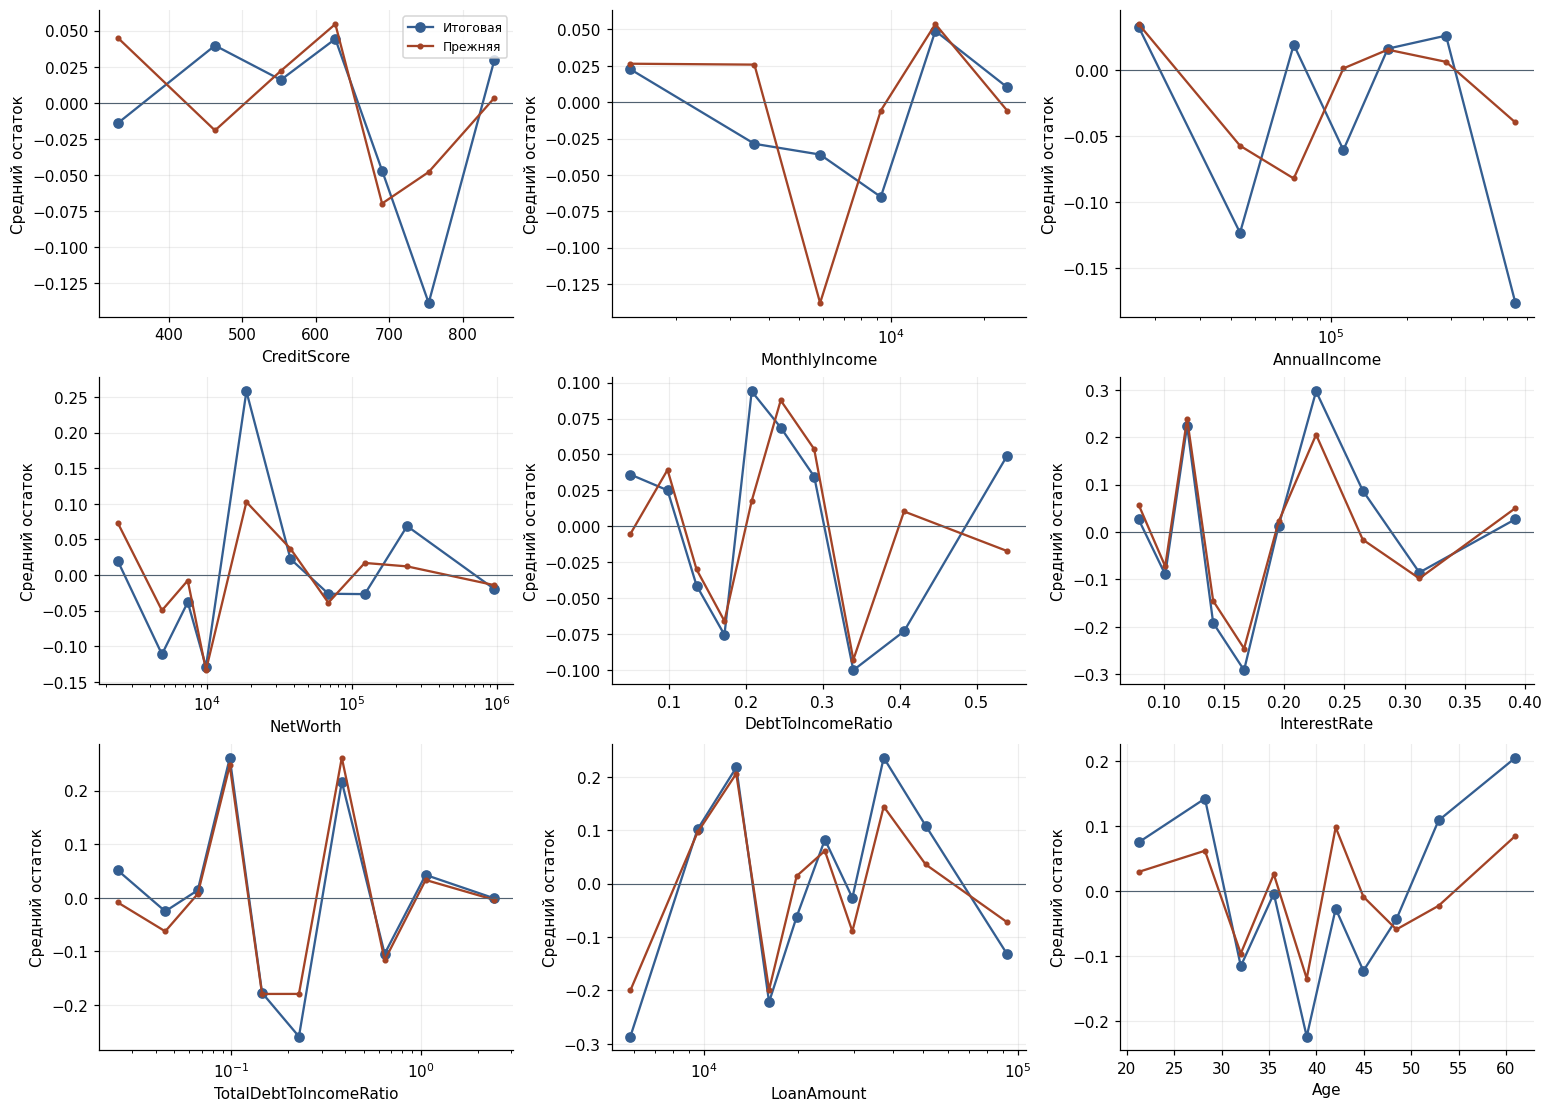

По повторной CV изменение MSE относительно прежней Ridge составляет **-0.3591**. Итоговая MSE лежит между 16.943 и 19.624 на отдельных фолдах.

In [21]:
residual_features = [
    "CreditScore", "MonthlyIncome", "AnnualIncome", "NetWorth", "DebtToIncomeRatio",
    "InterestRate", "TotalDebtToIncomeRatio", "LoanAmount", "Age",
]
residual_y = np.tile(dev_y, len(seeds))
ridge_residual = residual_y - cv_predictions[winner].ravel()
previous_residual = residual_y - cv_predictions[legacy.name].ravel()
fig, axes = plt.subplots(3, 3, figsize=(14, 10), layout="constrained")
for ax, col in zip(axes.flat, residual_features, strict=True):
    xx = np.tile(dev_complete[col].to_numpy(), len(seeds))
    xx_bins = pd.qcut(xx, 10, duplicates="drop")
    curve = (pd.DataFrame({"x": xx, "Итоговая": ridge_residual, "Прежняя": previous_residual})
             .groupby(xx_bins, observed=True).mean())
    ax.plot(curve.x, curve["Итоговая"], color="#345e91", marker="o", label="Итоговая")
    ax.plot(curve.x, curve["Прежняя"], color="#a34326", marker=".", label="Прежняя")
    ax.axhline(0, color="#516171", lw=.75)
    if col in {"MonthlyIncome", "AnnualIncome", "NetWorth", "TotalDebtToIncomeRatio", "LoanAmount"}:
        ax.set_xscale("log")
    ax.set(xlabel=col, ylabel="Средний остаток")
axes.flat[0].legend(fontsize=8)
plt.show()
display(Markdown(
    f"По повторной CV изменение MSE относительно прежней Ridge составляет "
    f"**{scores.loc[winner, 'MSE']-scores.loc[legacy.name, 'MSE']:+.4f}**. "
    f"Итоговая MSE лежит между {scores.loc[winner, 'Мин. MSE']:.3f} и "
    f"{scores.loc[winner, 'Макс. MSE']:.3f} на отдельных фолдах."
))

### 9.4. Где ошибалась первая модель

На отложенной выборке разрыв с кросс-валидацией в основном связан с тем, что ошибка выросла внутри диапазонов риска. Самый большой вклад дал интервал от 45 до 60. Само изменение долей диапазонов немного уменьшало разрыв.

Проверяю остатки в области, где риск резко растёт. Смотрю, как они связаны с длиной кредитной истории, надбавкой к базовой ставке, использованием лимита карты и возрастом. Сравнение входных признаков показывает, насколько похожи выборки по этим данным. Ошибку на тесте по нему вычислить нельзя.

In [22]:
baseline_v1 = ridge_age13
baseline_name = baseline_v1.name
base_oof = cv_predictions[baseline_name]
d = dev_complete
old_z, _ = build_load_index(d, "brace13")
mean_old_loss = np.square(dev_y[None, :] - base_oof).mean(axis=0)
mean_old_resid = (dev_y[None, :] - base_oof).mean(axis=0)
z_bands = pd.cut(old_z, [-np.inf, -.35, 0, .35, .7, 1.05, np.inf])
probe = pd.DataFrame({"Остаток": mean_old_resid, "Квадрат": mean_old_loss,
                      "История": d.LengthOfCreditHistory.to_numpy(),
                      "Надбавка": (d.InterestRate / d.BaseInterestRate - 1).to_numpy(),
                      "Использование лимита": d.CreditCardUtilizationRate.to_numpy(),
                      "Возраст старше 50": np.maximum(d.Age.to_numpy()-50,0)})
rows = []
for group, sample in probe.groupby(z_bands, observed=True):
    corr = sample.corr()["Остаток"].loc[probe.columns[2:]]
    rows.append({"Индекс": str(group), "Число": len(sample), "MSE": sample.Квадрат.mean(), **corr})
display(pd.DataFrame(rows).set_index("Индекс").round(3))
old_45_60 = mean_old_loss[(dev_y>=45)&(dev_y<60)].mean()
print(f"OOF MSE первой модели при RiskScore 45–60: {old_45_60:.4f}.")

hold_x_only = valid.iloc[holdout_indices].loc[:,predictor_columns].dropna()
all_x_smd = pd.DataFrame({
    "Holdout": (hold_x_only[num_columns].mean()-d[num_columns].mean())/d[num_columns].std(),
    "Test": (test[num_columns].mean()-d[num_columns].mean())/d[num_columns].std(),
})
display(all_x_smd.loc[all_x_smd.abs().max(axis=1).nlargest(8).index].round(3))
biggest_shift = all_x_smd.abs().max()
print(f"Макс. модуль стандартизированной разницы средних: "
      f"holdout {biggest_shift.Holdout:.3f}, test {biggest_shift.Test:.3f}.")
assert not valid[predictor_columns].duplicated().any()
assert test[predictor_columns].notna().all().all() and test.ID.is_unique

old_design = baseline_v1.encoder().fit(d).transform(d)
old_design -= old_design.mean(axis=0)
u_old, s_old, _ = np.linalg.svd(old_design, full_matrices=False)
ridge_hat = np.square(u_old) @ (s_old**2/(s_old**2+len(d)*baseline_v1.alpha))
rank_old = np.count_nonzero(s_old>s_old[0]*1e-10)
print(f"Прежняя матрица: {old_design.shape[1]} столбцов, численный ранг {rank_old}; "
      f"рычаг Ridge, 99-й процентиль {np.quantile(ridge_hat,.99):.4f}, "
      f"максимум {ridge_hat.max():.4f}.")
del old_design, u_old

,Число,MSE,История,Надбавка,Использование лимита,Возраст старше 50
Индекс,,,,,,
"(-inf, -0.35]",2634,7.794,0.045,0.006,0.078,-0.024
"(-0.35, 0.0]",579,24.564,-0.051,0.040,0.015,-0.017
"(0.0, 0.35]",598,48.788,-0.070,0.091,-0.014,0.099
"(0.35, 0.7]",655,59.447,-0.156,0.057,-0.079,0.014
"(0.7, 1.05]",632,30.168,-0.100,0.019,-0.069,0.023
"(1.05, inf]",2375,7.102,0.096,-0.035,0.026,-0.011


OOF MSE первой модели при RiskScore 45–60: 35.9784.


,Holdout,Test
TotalAssets,0.059,-0.003
NetWorth,0.057,-0.000
DebtToIncomeRatio,0.052,0.033
JobTenure,0.051,0.023
BankruptcyHistory,-0.050,-0.031
MonthlyLoanPayment,-0.050,0.013
CheckingAccountBalance,-0.043,-0.002
PaymentHistory,-0.036,-0.006


Макс. модуль стандартизированной разницы средних: holdout 0.059, test 0.033.


Прежняя матрица: 603 столбцов, численный ранг 598; рычаг Ridge, 99-й процентиль 0.0771, максимум 0.2268.


### 9.5. Признаки и проверка второй модели

В области перехода остатки первой модели сильнее связаны с длиной кредитной истории. В новый индекс добавляю поправку по четырём признакам — кредитной истории, надбавке к базовой ставке, использованию карты и возрасту старше 50 лет. Ещё добавляю признаки, которые сильнее влияют на прогноз вблизи перехода.

Для исходного признака $x_j$, центра окна $t$ и ширины $h$ новый признак равен

$$
\phi_{jt}(x)=x_j\exp\!\left(-\left(\frac{z-t}{h}\right)^2\right).
$$

Сравниваю 9 и 13 узлов, ширину перехода и окон, z-score и min-max, Ridge и Elastic Net. Также проверяю, полезно ли включать заявки с пропусками. Масштаб 0,24 усиливает штраф за вклад локального признака. Прогноз по всем столбцам строит одна линейная регрессия.

Варианты признаков составил после разбора прежних OOF-остатков на части данных для подбора. Во вложенной проверке выбираю признаки и штраф на внутренних фолдах. Внешний фолд служит для оценки. Настройки второй модели зафиксировал до итогового сравнения на отложенной выборке.

In [23]:
LOCAL_CENTERS = np.array([-.20, .10, .35, .60, .85, 1.10])
CORE_SHIFT = (-.24, .35, -.16, .10)
SMALL_SHIFT = (-.16, .25, -.12, .06)


def local_inputs(x):
    age = x.Age.to_numpy(dtype=float)
    credit = x.CreditScore.to_numpy(dtype=float)
    rate_ratio = (x.InterestRate / x.BaseInterestRate.clip(lower=1e-8) - 1).to_numpy()
    return {
        "история": x.LengthOfCreditHistory.to_numpy()/25-.60,
        "надбавка": rate_ratio,
        "использование карты": x.CreditCardUtilizationRate.to_numpy()-.28,
        "возраст 50+": np.maximum(age-50,0)/20,
        "возраст до 35": np.maximum(35-age,0)/15,
        "срок кредита": x.LoanDuration.to_numpy()/60-.88,
        "рейтинг ниже 650": np.maximum(650-credit,0)/250,
        "рейтинг выше 700": np.maximum(credit-700,0)/150,
    }


class TransitionFeatures(LoanFeatures):
    def __init__(self, spec):
        super().__init__(kind="focused", profile="brace-age13" if spec.nodes==13 else "brace-age",
                         missing="restore")
        self.spec = spec

    def _design(self, x):
        matrix = super()._design(x)
        inputs = local_inputs(x)
        z, directions = build_load_index(x, "brace13")
        if self.spec.shift is not None:
            components = np.column_stack(list(inputs.values())[:4])
            shift = components @ self.spec.shift
            grid = np.linspace(-.65, 1.25, self.spec.nodes)
            points = threshold_points(x)
            columns = []
            for values in directions.values():
                transition = erf((values[:,None]+shift[:,None]-grid)/self.spec.transition_width)
                for j in range(self.spec.nodes):
                    columns.extend([transition[:,j], transition[:,j]*points])
            matrix.loc[:, matrix.columns.str.startswith("Переход ")] = np.column_stack(columns)
        window = np.exp(-((z[:,None]-LOCAL_CENTERS)/self.spec.window_width)**2)
        extra = {
            f"Окно {center:g} × {name}": window[:,j]*values
            for j, center in enumerate(LOCAL_CENTERS)
            for name, values in inputs.items()
        }
        return pd.concat([matrix, pd.DataFrame(extra, index=x.index)], axis=1)

    def fit(self, frame):
        super().fit(frame)
        self.column_weights_[self.names_.str.startswith("Окно ")] = self.spec.window_scale
        if self.spec.minmax:
            x = self._filled(self._prepared(frame))
            self.scaler_ = MinMaxScaler().fit(self._design(x))
            self.column_weights_ *= 4
        return self


@dataclass(frozen=True)
class TransitionExperiment(Experiment):
    shift: tuple | None = CORE_SHIFT
    nodes: int = 13
    transition_width: float = .18
    window_width: float = .60
    window_scale: float = .24
    minmax: bool = False

    def encoder(self):
        return TransitionFeatures(self)

    def features_key(self):
        return (super().features_key(), self.shift, self.nodes, self.transition_width,
                self.window_width, self.window_scale, self.minmax)


def transition_spec(name, alpha=.013, penalty="l2", **kwargs):
    return TransitionExperiment(name, "transition", alpha=alpha, penalty=penalty, **kwargs)


core_grid = [
    transition_spec("Ridge · поправка 13, λ=.005", .005),
    transition_spec("Ridge · поправка 13, λ=.008", .008),
    transition_spec("Ridge · поправка 13, λ=.013"),
    transition_spec("Ridge · поправка 13, λ=.020", .020),
    transition_spec("Ridge · поправка 9, λ=.008", .008, nodes=9),
    transition_spec("Ridge · слабый сдвиг", .013, shift=SMALL_SHIFT),
]
ablations = [
    transition_spec("Ridge · только окна", .008, shift=None),
    transition_spec("Ridge · узкие окна", .008, window_width=.44),
    transition_spec("Ridge · широкий переход", .008, transition_width=.28),
    transition_spec("Ridge · сильный штраф окон", .008, window_scale=.12),
    transition_spec("Ridge · min-max", .008, minmax=True),
    transition_spec("Ridge · с неполными заявками", .013, missing="restore"),
    transition_spec("Elastic Net · поправка 13, λ=.006", .006, "elasticnet"),
    transition_spec("Elastic Net · поправка 13, λ=.012", .012, "elasticnet"),
]
new_specs = core_grid + ablations
new_by_name = {spec.name:spec for spec in new_specs}
new_oof = {spec.name:np.full_like(base_oof,np.nan) for spec in new_specs}
new_folds = {spec.name:[] for spec in new_specs}
for rep, seed in enumerate(seeds):
    for spec, va, pred, _, _, width, done in compare_folds(dev_complete, dev_partial, 5, seed,
                                                          new_specs, check_partial=False):
        assert np.isnan(new_oof[spec.name][rep,va]).all()
        new_oof[spec.name][rep,va] = pred
        new_folds[spec.name].append((mse(dev_y[va],pred),width,done))

baseline_cv = scores.loc[baseline_name,"MSE"]
new_rows = {}
for spec in new_specs:
    current = new_oof[spec.name]
    assert np.isfinite(current).all()
    mses, widths, done = map(np.asarray,zip(*new_folds[spec.name],strict=True))
    score = mse(np.tile(dev_y,len(seeds)),current.ravel())
    new_rows[spec.name] = {
        "Столбцы": int(np.median(widths)), "λ": spec.alpha, "MSE OOF": score,
        "SD фолдов": mses.std(ddof=1), "Δ к первой модели": score-baseline_cv,
        "Сошлось": int(done.sum()),
    }
v2_scores = pd.DataFrame(new_rows).T.sort_values("MSE OOF")
display(v2_scores.round(5))
finalists_new = [baseline_v1,*core_grid]

,Столбцы,λ,MSE OOF,SD фолдов,Δ к первой модели,Сошлось
Ridge · сильный штраф окон,651.0,0.008,18.19502,0.90063,-0.37813,10.0
"Ridge · поправка 13, λ=.013",651.0,0.013,18.20339,0.87697,-0.36976,10.0
"Ridge · поправка 13, λ=.008",651.0,0.008,18.20954,0.88939,-0.36361,10.0
"Ridge · поправка 9, λ=.008",499.0,0.008,18.21941,0.85929,-0.35374,10.0
"Elastic Net · поправка 13, λ=.012",651.0,0.012,18.22021,0.86157,-0.35294,10.0
Ridge · слабый сдвиг,651.0,0.013,18.22303,0.85903,-0.35012,10.0
"Ridge · поправка 13, λ=.020",651.0,0.020,18.22380,0.86715,-0.34935,10.0
Ridge · узкие окна,651.0,0.008,18.23026,0.87766,-0.34289,10.0
Ridge · широкий переход,651.0,0.008,18.23297,0.83538,-0.34018,10.0
"Ridge · поправка 13, λ=.005",651.0,0.005,18.23900,0.90209,-0.33415,10.0


In [24]:
v1_outer = np.full(len(dev_y),np.nan)
v2_outer = np.full(len(dev_y),np.nan)
nested_v2_rows = []
coefficient_rows = []
outer_complete = kfold_indices(len(dev_complete),3,random_state=516)
outer_partial = kfold_indices(len(dev_partial),3,random_state=516)
for i, ((tr,va),(pt,_)) in enumerate(zip(outer_complete,outer_partial,strict=True),start=1):
    a,b = dev_complete.iloc[tr],dev_complete.iloc[va]
    ap = dev_partial.iloc[pt]
    y_train = a[TARGET].to_numpy()
    errors = {spec.name:0. for spec in finalists_new}
    for spec, v, prediction, *_ in compare_folds(a,ap,3,209+i,finalists_new,check_partial=False):
        errors[spec.name] += np.square(y_train[v]-prediction).sum()
    chosen_name = min(errors,key=errors.get)
    local = baseline_v1 if chosen_name==baseline_name else new_by_name[chosen_name]
    assert not set(a.ApplicationDate).intersection(b.ApplicationDate)
    for label, spec, vector in [("Первая",baseline_v1,v1_outer),("Новая",local,v2_outer)]:
        enc, fit = fit_experiment(spec,a)
        vector[va] = fit.predict(enc.transform(b))
        coefficient_rows.append((i,label,np.linalg.norm(fit.coef_),np.abs(fit.coef_).max()))
    nested_v2_rows.append((i,local.name,mse(dev_y[va],v1_outer[va]),mse(dev_y[va],v2_outer[va])))
assert np.isfinite(v1_outer).all() and np.isfinite(v2_outer).all()
nested_v1_fixed_mse = mse(dev_y,v1_outer)
nested_v2_mse = mse(dev_y,v2_outer)
display(pd.DataFrame(nested_v2_rows,columns=["Фолд","Модель внутри","Первая","Новая"]).round(5))
display(pd.DataFrame(coefficient_rows,columns=["Фолд","Версия","Норма L2","max |w|"]).round(5))
print(f"Вложенная OOF MSE: первая фиксированная {nested_v1_fixed_mse:.6f}, "
      f"подбор новой {nested_v2_mse:.6f}.")

eligible = v2_scores.loc[[s.name for s in core_grid]].sort_values("MSE OOF")
near_best = eligible[eligible["MSE OOF"]<=eligible["MSE OOF"].min()+.01]
selected_v2 = new_by_name[near_best.sort_values(["Столбцы","MSE OOF"]).index[0]]
winner_v2 = selected_v2.name
pred_v2 = new_oof[winner_v2]
actual2 = np.tile(dev_y,len(seeds))
v2_metrics = evaluate(actual2,pred_v2.ravel())
old_losses = np.square(base_oof-dev_y[None,:])
v2_losses = np.square(pred_v2-dev_y[None,:])
first_folds = []
second_folds = []
for rep, seed in enumerate(seeds):
    for _, va in kfold_indices(len(dev_y),5,random_state=seed):
        first_folds.append(old_losses[rep,va].mean())
        second_folds.append(v2_losses[rep,va].mean())
paired_v2 = pd.DataFrame({"Первая":first_folds,"Новая":second_folds})
paired_v2["Δ"] = paired_v2.Новая-paired_v2.Первая
display(paired_v2.round(5))
print(f"До проверки holdout: {winner_v2}. Лучше на {(paired_v2['Δ']<0).sum()}/10 фолдах.")
assert v2_metrics["MSE"] < baseline_cv-.10
assert nested_v2_mse < nested_v1_fixed_mse-.08
assert (paired_v2["Δ"]<0).sum() >= 8
ridge_residual = actual2-pred_v2.ravel()
residual_y = actual2
selected = selected_v2

,Фолд,Модель внутри,Первая,Новая
0,1,"Ridge · поправка 13, λ=.020",18.24193,17.86101
1,2,"Ridge · поправка 13, λ=.020",19.87193,19.45023
2,3,Ridge · слабый сдвиг,17.94309,17.40950


,Фолд,Версия,Норма L2,max |w|
0,1,Первая,10.75532,2.67011
1,1,Новая,6.74076,2.58681
2,2,Первая,11.00668,2.67490
3,2,Новая,6.72799,2.59648
4,3,Первая,10.82547,2.50799
5,3,Новая,7.29567,2.45174


Вложенная OOF MSE: первая фиксированная 18.685650, подбор новой 18.240248.


,Первая,Новая,Δ
0,18.38379,17.75458,-0.62921
1,19.62450,19.12395,-0.50054
2,18.56697,18.23381,-0.33316
3,19.29621,19.20900,-0.08721
4,16.94306,16.44459,-0.49847
5,19.12339,19.22780,0.10442
6,17.78489,17.37011,-0.41478
7,18.81934,18.26029,-0.55905
8,18.39067,18.30510,-0.08557
9,18.79811,18.10415,-0.69396


До проверки holdout: Ridge · поправка 13, λ=.013. Лучше на 9/10 фолдах.


### 9.6. Ошибка в разных диапазонах риска

Для заявок с фактическим `RiskScore` от 45 до 60 OOF MSE снизилась с 35,98 до 34,49. Группы нужны только для разбора ошибок. При прогнозировании модель получает признаки заявки.

,n,first,second,Δ
"[0.0, 30.0)",1100,9.77149,9.64946,-0.12203
"[30.0, 45.0)",2716,19.17505,19.03849,-0.13656
"[45.0, 60.0)",1242,35.97838,34.48524,-1.49313
"[60.0, 75.0)",1966,12.94611,12.66154,-0.28456
"[75.0, inf)",449,12.98862,13.33563,0.34701


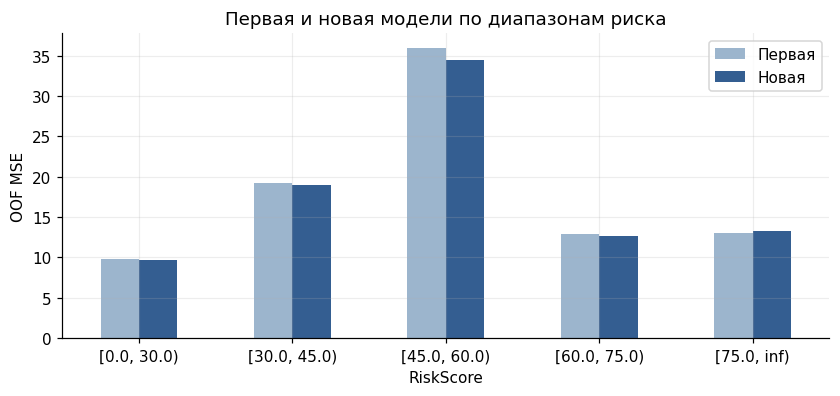

In [25]:
delta_by_risk = pd.DataFrame({
    "Цель":dev_y, "Первая MSE":old_losses.mean(axis=0), "Новая MSE":v2_losses.mean(axis=0)
})
bands = pd.cut(dev_y,[0,30,45,60,75,np.inf],right=False)
band_scores = delta_by_risk.groupby(bands,observed=True).agg(
    n=("Цель","size"), first=("Первая MSE","mean"), second=("Новая MSE","mean"))
band_scores["Δ"] = band_scores["second"]-band_scores["first"]
display(band_scores.round(5))
ax=band_scores[["first","second"]].rename(columns={"first":"Первая","second":"Новая"}).plot.bar(
    figsize=(9,3.6),rot=0,color=["#9cb5cd","#345e91"],xlabel="RiskScore",ylabel="OOF MSE",
    title="Первая и новая модели по диапазонам риска")
plt.show()

## 10. Отложенная выборка и выгрузка

Сравниваю обе модели на одних и тех же отложенных заявках. Для каждого диапазона фактического `RiskScore` обозначаю доли заявок при подборе и на отложенной выборке через $q_d,q_h$, а ошибки MSE в этом диапазоне — через $m_d,m_h$. Так можно отдельно увидеть влияние состава выборки и изменение ошибки внутри диапазонов.

$$
\Delta_{\text{состав}}=\sum_g(q_h-q_d)m_d.
$$

$$
\Delta_{\text{ошибка}}=\sum_g q_h(m_h-m_d).
$$

Чтобы оценить разброс разницы, беру повторные выборки из отложенных строк с возвращением. Затем обучаю итоговую модель на 9 332 заявках без пропусков. Ноутбук сохраняет `submission_candidate_v2.csv` и проверяет его по `ex.csv`. Итоговый `submission.csv` — побайтная копия этой выгрузки.

Строк         MSE       MAE        R²      MAPE
Модель   Заявки                                                    
Прежняя  Полные    1859.0   19.438680  3.051487  0.934548  0.071525
         Неполные    99.0  109.207264  8.065853  0.650985  0.165858
Итоговая Полные    1859.0   18.677866  2.988700  0.937110  0.070082
         Неполные    99.0  111.767707  8.197955  0.642802  0.167860

,Строк holdout,OOF MSE,Holdout MSE,Средний остаток holdout,Вклад состава,Вклад внутригрупповой ошибки
"[0.0, 30.0)",304,9.6495,11.4741,-2.0593,0.1576,0.2984
"[30.0, 45.0)",655,19.0385,19.0994,-0.8233,-0.2114,0.0214
"[45.0, 60.0)",288,34.4852,38.2983,1.8236,-0.3889,0.5907
"[60.0, 75.0)",518,12.6615,12.3303,0.7599,0.1971,-0.0923
"[75.0, inf)",94,13.3356,13.9038,2.0077,-0.1269,0.0287


Разрыв holdout−CV: +0.4745. Состав: -0.3725, внутри диапазонов: +0.8470.
Наибольший по модулю вклад внутри диапазонов: [45.0, 60.0).
Holdout MSE, 95% бутстрэп: [16.837, 20.669]. Изменение к прежней MSE: -0.7608, 95% парный интервал [-1.300, -0.242].


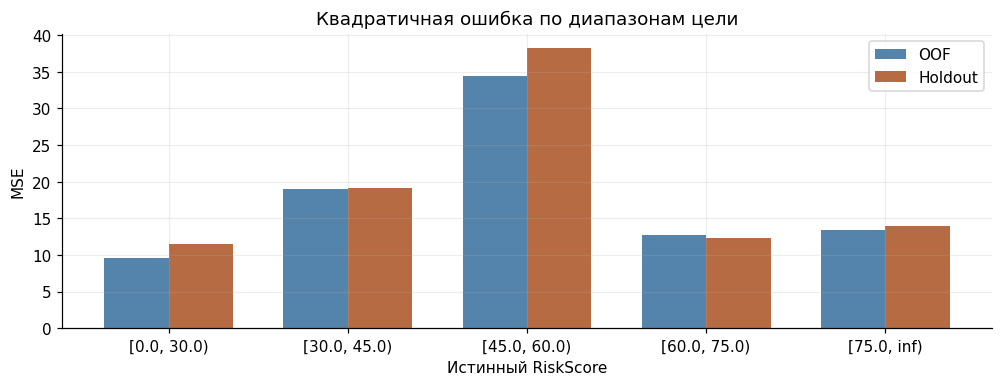

In [26]:
holdout = valid.iloc[holdout_indices]
assert not set(development.ApplicationDate).intersection(holdout.ApplicationDate)
hold_complete = holdout.dropna()
hold_partial = holdout.loc[holdout.isna().any(axis=1)]


evaluation = {}
hold_errors = {}
for label, spec in [("Прежняя", baseline_v1), ("Итоговая", selected)]:
    part = development if spec.use_partial else dev_complete
    encoder, model = fit_experiment(spec, part)
    for segment, frame in [("Полные", hold_complete), ("Неполные", hold_partial)]:
        truth = frame[TARGET].to_numpy()
        forecast = model.predict(encoder.transform(frame))
        hold_errors[label, segment] = truth-forecast
        evaluation[label, segment] = {"Строк": len(frame), **evaluate(truth, forecast)}
hold_results = pd.DataFrame(evaluation).T
hold_results.index.names = ["Модель", "Заявки"]
display(hold_results.round(6))

hold_y = hold_complete[TARGET].to_numpy()
old_hold = hold_errors["Прежняя", "Полные"]
new_hold = hold_errors["Итоговая", "Полные"]
groups = [0, 30, 45, 60, 75, np.inf]


def group_loss(ys, errors):
    by = pd.cut(ys, groups, right=False)
    frame = pd.DataFrame({"остаток": errors, "квадрат": errors**2})
    out = frame.groupby(by, observed=True).agg(n=("остаток", "size"),
                                               bias=("остаток", "mean"), MSE=("квадрат", "mean"))
    return out.assign(weight=out.n/len(ys))


dev_groups = group_loss(residual_y, ridge_residual)
hold_groups = group_loss(hold_y, new_hold)
mix = (hold_groups.weight-dev_groups.weight)*dev_groups.MSE
inside = hold_groups.weight*(hold_groups.MSE-dev_groups.MSE)
group_comparison = pd.DataFrame({
    "Строк holdout": hold_groups.n,
    "OOF MSE": dev_groups.MSE, "Holdout MSE": hold_groups.MSE,
    "Средний остаток holdout": hold_groups.bias,
    "Вклад состава": mix, "Вклад внутригрупповой ошибки": inside,
})
gap = mse(hold_y, hold_y-new_hold)-v2_metrics["MSE"]
np.testing.assert_allclose(mix.sum()+inside.sum(), gap, atol=1e-10)
display(group_comparison.round(4))
rng_boot = np.random.default_rng(977)
bootstrap_indices = rng_boot.integers(len(hold_y), size=(1800, len(hold_y)))
boot_mse = (new_hold**2)[bootstrap_indices].mean(axis=1)
boot_delta = (new_hold**2-old_hold**2)[bootstrap_indices].mean(axis=1)
ci = np.quantile(boot_mse, [.025,.975])
delta_ci = np.quantile(boot_delta, [.025,.975])
print(f"Разрыв holdout−CV: {gap:+.4f}. Состав: {mix.sum():+.4f}, внутри диапазонов: {inside.sum():+.4f}.")
print(f"Наибольший по модулю вклад внутри диапазонов: {inside.abs().idxmax()}.")
print(f"Holdout MSE, 95% бутстрэп: [{ci[0]:.3f}, {ci[1]:.3f}]. "
      f"Изменение к прежней MSE: {np.mean(new_hold**2-old_hold**2):+.4f}, "
      f"95% парный интервал [{delta_ci[0]:+.3f}, {delta_ci[1]:+.3f}].")

fig, ax = plt.subplots(figsize=(9, 3.4), layout="constrained")
position = np.arange(len(group_comparison))
ax.bar(position-.18, group_comparison["OOF MSE"], .36, color="#5484ac", label="OOF")
ax.bar(position+.18, group_comparison["Holdout MSE"], .36, color="#b66b42", label="Holdout")
ax.set_xticks(position, [str(g) for g in group_comparison.index])
ax.set(xlabel="Истинный RiskScore", ylabel="MSE", title="Квадратичная ошибка по диапазонам цели")
ax.legend()
plt.show()

In [27]:
fit_rows = valid if selected.use_partial else valid.loc[complete]
final_encoder, final_model = fit_experiment(selected, fit_rows)
final_matrix = final_encoder.transform(test)
prediction = final_model.predict(final_matrix)
assert prediction.shape == (5000,) and np.isfinite(prediction).all()
submission_file = Path("submission_candidate_v2.csv")
pd.DataFrame({"ID": test.ID, TARGET: prediction}).to_csv(submission_file, index=False, float_format="%.12f")
check_csv = pd.read_csv(submission_file)
assert check_csv.shape == example.shape == (5000, 2)
assert check_csv.columns.equals(example.columns) and check_csv.ID.is_unique
assert pd.api.types.is_numeric_dtype(check_csv[TARGET]) and np.isfinite(check_csv[TARGET]).all()
np.testing.assert_array_equal(check_csv.ID, test.ID)
np.testing.assert_array_equal(check_csv.ID, example.ID)
np.testing.assert_allclose(check_csv[TARGET], prediction, atol=6e-13, rtol=0)
print(f"Финальный fit: {len(fit_rows)} строк, {final_matrix.shape[1]} столбцов.")
print(f"CSV: {len(check_csv)} строк, прогнозы конечны, порядок ID совпадает.")

Финальный fit: 9332 строк, 651 столбцов.
CSV: 5000 строк, прогнозы конечны, порядок ID совпадает.


## 11. Итоги

После доработки признаков MSE на повторной кросс-валидации снизилась с **18,5732** до **18,2034**. Вложенная кросс-валидация дала **18,2402**, а на отложенной выборке MSE составила **18,6779**. Для итоговой модели использовал **9 332 строки и 651 признак**.

| Посылка | Kaggle Public Score |
|---|---:|
| Первая | 19,2146154 |
| Вторая | **18,9916942** |

Вторая посылка получила статус **Complete** и прошла порог строго ниже **19,00**. Public Score — результат на публичной части теста Kaggle. Private Score не указан.

### Что проверено

| Задание | Раздел | Проверка |
|---|---|---|
| EDA | 1–2, 8–10 | Графики, корреляционная матрица и остатки |
| Z-score и min-max | 3, 7.1 | Сравнение со sklearn, константы, NaN и обратное преобразование |
| МНК, GD и SGD | 5, 7.1, 8 | Градиент, сходимость, зависимые признаки и сравнение со sklearn |
| K-fold и LOO | 6, 7.1, 8–9 | Сравнение индексов со sklearn, PRESS и прямой LOO |
| MSE, MAE, $R^2$ и MAPE | 4, 7.1 | Ручные ответы, сравнение со sklearn и граничные случаи |
| L1, L2 и Elastic Net | 7, 9 | Сравнение коэффициентов, нулевые веса и ошибка по CV |
| Lp | 7 | Четыре значения $p$ и условие стационарности |
| CSV для Kaggle | 10 | 5 000 строк, порядок `ID` и проверка предсказаний |

*Вывод следующей ячейки сохранён до второй отправки. Официальный Public Score приведён в таблице выше.*

In [28]:
hold_mse = hold_results.loc[("Итоговая","Полные"),"MSE"]
display(Markdown(
    f"**Повторная CV.** MSE первой посылки {baseline_cv:.4f}, новой **{v2_metrics['MSE']:.4f}**. "
    f"Вложенная MSE для подбора новой модели **{nested_v2_mse:.4f}**. "
    f"На полных отложенных заявках MSE **{hold_mse:.4f}**. "
    f"Итоговое обучение использовало {len(fit_rows)} строк, матрица содержит {final_matrix.shape[1]} столбцов. "
    "Файл второй посылки готов для загрузки. Её Public Score пока не получен."
))

**Повторная CV.** MSE первой посылки 18.5732, новой **18.2034**. Вложенная MSE для подбора новой модели **18.2402**. На полных отложенных заявках MSE **18.6779**. Итоговое обучение использовало 9332 строк, матрица содержит 651 столбцов. Файл второй посылки готов для загрузки. Её Public Score пока не получен.